# Analysis of Jannik Sinner's Performance

## Ranking, serve, break points, and winning percentage on different surfaces (2018–2025)

**Author:** Galiya Galimova | Tennis Analyst

**Period:** 2018–2025  

**Data:** 22018-2025 ATP Tour matches (source: Jeff Sackmann's [github](https://github.com/JeffSackmann))

---

### Executive Summary

**Objective:** To analyze Jannik Sinner's key performance indicators across surfaces (hard, clay, grass) and match outcome (win/loss).

**Method:** Exploratory data analysis

**Metrics:**
- Rank
- Serve: number of serve points, number of first serves made, number of first-serve points won, number of second-serve points won, number of aces, number of doubles faults
- Break Points: number of break points saved, number of break points faced
- Surface: Hard, Clay, Grass

**Key Insights:**
- From April 2019 to January 2020, Yannik Sinner climbed 235 positions. In November 2021, he broke into the TOP 10 of the ATP ranking.
- Jannik Sinner has won 11 ATP 250 titles, 2 ATP 500 titles, 5 Masters titles, and 4 Grand Slam titles. His win percentage on hard court is 79.5%, 74.4% on grass, and 71.4% on clay.
- Jannik Sinner's serve performance is highest on grass, followed by hard court, and lowest on clay. On grass, first serve points won is 79%, second serve points won is 59%, and total serve points won is 71%. On hard court serve performance metrics are 77%, 56%, and 69% respectively. On clay these metrics are 72%, 55%, and 65% respectively.
- Jannik Sinner has the lowest return points won percentage (38%). On clay he has the highest return points won (43%). On hard surface this metric is 41%.
- Jannik Sinner faces the most break points on clay (7.69%) but saves the lowest percentage (61.17%). On grass, he faces the fewest break points (4.97%) and saves the most (69.07%). Hard court performance is in between. He faces 6.38% of break points and saves 67.22% of break points.




Three sets of metrics are analyzed:

1. **Rank evolution** – how Sinner's position in the ATP rankings has changed. 
2. **Serve & Return & Break points** — percentage of wins on first and second serves, aces, double faults, break points faced and saved.
3. **Win percentage** — percentage of wins overall and on each surface.

### Import the data

In [1]:
#Import libraries
import numpy as np 
import pandas as pd
import seaborn as sns 
import matplotlib.pyplot as plt
%matplotlib inline

import warnings
warnings.filterwarnings('ignore')

In [2]:
#Display all columns
pd.set_option('display.max_columns', None)

In [3]:
#Import the ATP data from 2018 to 2025
atp_2018 = pd.read_csv('atp_matches_2018.csv')
atp_2019 = pd.read_csv('atp_matches_2019.csv')
atp_2020 = pd.read_csv('atp_matches_2020.csv')
atp_2021 = pd.read_csv('atp_matches_2021.csv')
atp_2022 = pd.read_csv('atp_matches_2022.csv')
atp_2023 = pd.read_csv('atp_matches_2023.csv')
atp_2024 = pd.read_csv('atp_matches_2024.csv')
atp_2025 = pd.read_csv('atp_matches_2025.csv')

In [4]:
#Keep the required columns in the dataset "atp_2025"
atp_2025 = atp_2025[['tourney_id', 'tourney_name', 'surface', 'draw_size', 'tourney_level', 'tourney_date', \
                     'match_num', 'winner_id', 'winner_seed', 'winner_entry', 'winner_name', 'winner_hand', \
                     'winner_ht', 'winner_ioc', 'winner_age', 'loser_id', 'loser_seed', 'loser_entry', 'loser_name', \
                     'loser_hand', 'loser_ht', 'loser_ioc', 'loser_age', 'score', 'best_of', 'round', 'minutes', \
                     'w_ace', 'w_df', 'w_svpt', 'w_1stIn', 'w_1stWon', 'w_2ndWon', 'w_SvGms', 'w_bpSaved', \
                     'w_bpFaced', 'l_ace', 'l_df', 'l_svpt', 'l_1stIn', 'l_1stWon', 'l_2ndWon', 'l_SvGms', \
                     'l_bpSaved', 'l_bpFaced', 'winner_rank', 'winner_rank_points', 'loser_rank', 'loser_rank_points']]

In [5]:
#Combine all datasets into one dataset
atp = pd.concat([atp_2018, atp_2019, atp_2020, atp_2021, atp_2022, atp_2023, atp_2024, atp_2025])
atp.head()

,tourney_id,tourney_name,surface,draw_size,tourney_level,tourney_date,match_num,winner_id,winner_seed,winner_entry,winner_name,winner_hand,winner_ht,winner_ioc,winner_age,loser_id,loser_seed,loser_entry,loser_name,loser_hand,loser_ht,loser_ioc,loser_age,score,best_of,round,minutes,w_ace,w_df,w_svpt,w_1stIn,w_1stWon,w_2ndWon,w_SvGms,w_bpSaved,w_bpFaced,l_ace,l_df,l_svpt,l_1stIn,l_1stWon,l_2ndWon,l_SvGms,l_bpSaved,l_bpFaced,winner_rank,winner_rank_points,loser_rank,loser_rank_points
0,2018-M020,Brisbane,Hard,32.0,A,20180101,271.0,105992,NaN,NaN,Ryan Harrison,R,185.0,USA,25.6,104919,NaN,NaN,Leonardo Mayer,R,188.0,ARG,30.6,6-4 3-6 6-2,3,R32,123.0,9.0,2.0,82.0,49.0,39.0,20.0,13.0,8.0,9.0,10.0,3.0,80.0,47.0,33.0,19.0,14.0,1.0,4.0,47.0,1010.0,52.0,909.0
1,2018-M020,Brisbane,Hard,32.0,A,20180101,272.0,111577,NaN,NaN,Jared Donaldson,R,188.0,USA,21.2,111442,NaN,WC,Jordan Thompson,R,183.0,AUS,23.7,6-2 6-4,3,R32,90.0,5.0,3.0,58.0,32.0,25.0,14.0,9.0,4.0,5.0,3.0,5.0,62.0,41.0,25.0,7.0,9.0,7.0,11.0,54.0,890.0,94.0,593.0
2,2018-M020,Brisbane,Hard,32.0,A,20180101,273.0,104797,NaN,NaN,Denis Istomin,R,185.0,UZB,31.3,106000,7.0,NaN,Damir Dzumhur,R,175.0,BIH,25.6,6-7(4) 6-3 6-2,3,R32,145.0,7.0,0.0,94.0,66.0,48.0,12.0,14.0,9.0,11.0,8.0,6.0,120.0,53.0,37.0,29.0,15.0,10.0,16.0,63.0,809.0,30.0,1391.0
3,2018-M020,Brisbane,Hard,32.0,A,20180101,275.0,200282,NaN,WC,Alex De Minaur,R,183.0,AUS,18.8,105449,NaN,NaN,Steve Johnson,R,188.0,USA,28.0,7-6(7) 6-4,3,R32,104.0,9.0,3.0,66.0,37.0,32.0,17.0,11.0,2.0,3.0,6.0,2.0,80.0,43.0,33.0,17.0,11.0,4.0,6.0,208.0,245.0,44.0,1055.0
4,2018-M020,Brisbane,Hard,32.0,A,20180101,276.0,111581,NaN,Q,Michael Mmoh,R,188.0,USA,19.9,105643,NaN,NaN,Federico Delbonis,L,193.0,ARG,27.2,6-3 6-4,3,R32,69.0,5.0,4.0,55.0,38.0,32.0,11.0,10.0,3.0,3.0,4.0,0.0,45.0,35.0,28.0,5.0,9.0,0.0,2.0,175.0,299.0,68.0,755.0


In [6]:
#Display information about a dataframe including the index dtype and columns, non-NA values and memory usage
atp.info()

<class 'pandas.core.frame.DataFrame'>
Index: 21821 entries, 0 to 2943
Data columns (total 49 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   tourney_id          21821 non-null  object 
 1   tourney_name        21821 non-null  object 
 2   surface             21768 non-null  object 
 3   draw_size           21805 non-null  float64
 4   tourney_level       21821 non-null  object 
 5   tourney_date        21821 non-null  int64  
 6   match_num           21332 non-null  float64
 7   winner_id           21821 non-null  object 
 8   winner_seed         8973 non-null   float64
 9   winner_entry        3190 non-null   object 
 10  winner_name         21821 non-null  object 
 11  winner_hand         21803 non-null  object 
 12  winner_ht           21714 non-null  float64
 13  winner_ioc          21819 non-null  object 
 14  winner_age          21816 non-null  float64
 15  loser_id            21821 non-null  object 
 16  loser_seed

In [7]:
#Convert 'tourney_date' from int64 to datetime
atp['tourney_date'] = pd.to_datetime(atp.tourney_date, format = '%Y%m%d')

In [8]:
#Drop columns 'winner_seed', 'winner_entry', 'loser_seed', 'loser_entry'
atp = atp.drop(['winner_seed', 'winner_entry', 'loser_seed', 'loser_entry'], axis = 1)

In [9]:
#Generate descriptive statistics including number of values, mean, standard deviation
atp.describe()

,draw_size,tourney_date,match_num,winner_ht,winner_age,loser_ht,loser_age,best_of,minutes,w_ace,w_df,w_svpt,w_1stIn,w_1stWon,w_2ndWon,w_SvGms,w_bpSaved,w_bpFaced,l_ace,l_df,l_svpt,l_1stIn,l_1stWon,l_2ndWon,l_SvGms,l_bpSaved,l_bpFaced,winner_rank,winner_rank_points,loser_rank,loser_rank_points
count,21805.000000,21821,21332.000000,21714.000000,21816.000000,21532.000000,21815.000000,21821.000000,20473.000000,20935.000000,20935.000000,20935.000000,20935.000000,20935.000000,20934.000000,20934.000000,20934.000000,20934.000000,20934.000000,20934.000000,20934.000000,20934.000000,20934.000000,20934.000000,20934.000000,20934.000000,20934.000000,21729.000000,21729.000000,21541.000000,21541.000000
mean,60.775877,2022-01-24 15:45:11.754731776,228.729655,187.658331,26.873326,186.700678,27.147790,3.371569,114.661066,7.221877,2.611607,79.304036,50.034010,37.935801,16.199866,12.758001,3.458775,4.988631,5.479841,3.244817,82.292968,50.668052,34.125776,14.689166,12.518821,4.770756,8.456243,75.332275,1863.510746,106.292187,1185.586231
min,2.000000,2018-01-01 00:00:00,1.000000,3.000000,14.900000,15.000000,14.500000,3.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,1.000000,1.000000,1.000000
25%,32.000000,2019-10-14 00:00:00,159.000000,183.000000,23.411000,183.000000,23.700000,3.000000,83.000000,3.000000,1.000000,58.000000,36.000000,28.000000,11.000000,10.000000,1.000000,2.000000,2.000000,1.000000,61.000000,37.000000,24.000000,10.000000,9.000000,2.000000,5.000000,18.000000,702.000000,35.000000,560.000000
50%,32.000000,2022-04-11 00:00:00,274.000000,188.000000,26.400000,185.000000,26.845000,3.000000,107.000000,6.000000,2.000000,74.000000,47.000000,36.000000,15.000000,12.000000,3.000000,4.000000,4.000000,3.000000,77.000000,47.000000,32.000000,14.000000,12.000000,4.000000,8.000000,46.000000,1075.000000,66.000000,854.000000
75%,128.000000,2024-02-12 00:00:00,289.000000,193.000000,29.800000,191.000000,30.100000,3.000000,139.000000,10.000000,4.000000,95.000000,60.000000,45.000000,20.000000,15.000000,5.000000,7.000000,8.000000,4.000000,99.000000,61.000000,42.000000,19.000000,15.000000,7.000000,11.000000,85.000000,2130.000000,109.000000,1318.000000
max,128.000000,2025-12-22 00:00:00,1701.000000,211.000000,44.600000,211.000000,43.900000,5.000000,396.000000,64.000000,26.000000,278.000000,198.000000,166.000000,56.000000,49.000000,23.000000,30.000000,67.000000,26.000000,291.000000,218.000000,171.000000,52.000000,50.000000,27.000000,38.000000,2068.000000,12415.000000,2146.000000,12355.000000
std,43.355708,NaN,151.652346,7.190912,4.549739,7.162161,4.572268,0.777883,42.564524,5.602551,2.312842,29.196623,19.171297,13.730704,6.726704,4.240388,3.063227,4.000748,5.072300,2.533569,29.019247,19.274557,14.457987,6.919919,4.232710,3.279558,4.152444,126.758299,2071.572657,165.057647,1249.289960


In [10]:
#Display dataset size
atp.shape

(21821, 45)

**Conclusion:** We have the data for the period from 2018 to 2025. The dataset consists of 21821 rows and 45 columns. 

Let's move on to selecting ATP matches in which Jannik Sinner participated.

### Select Jannik Sinner's ATP matches

In [11]:
#Select matches where Jannik Sinner participated
js = atp[(atp.winner_name.isin(['Jannik Sinner'])) | (atp.loser_name.isin(['Jannik Sinner']))]\
    .reset_index(drop=True)

In [12]:
#Remove Finals' and Cup's matches
words_to_remove = ['Tour Finals', 'NextGen Finals', 'Atp Cup', 'Davis Cup', 'ATP Finals']
js_atp = js[~js['tourney_name'].str.contains('|'.join(words_to_remove), case = False, na = False)]\
        .reset_index(drop=True)

In [13]:
#Display information about a dataframe
js_atp.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 379 entries, 0 to 378
Data columns (total 45 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   tourney_id          379 non-null    object        
 1   tourney_name        379 non-null    object        
 2   surface             379 non-null    object        
 3   draw_size           379 non-null    float64       
 4   tourney_level       379 non-null    object        
 5   tourney_date        379 non-null    datetime64[ns]
 6   match_num           359 non-null    float64       
 7   winner_id           379 non-null    object        
 8   winner_name         379 non-null    object        
 9   winner_hand         379 non-null    object        
 10  winner_ht           379 non-null    float64       
 11  winner_ioc          379 non-null    object        
 12  winner_age          379 non-null    float64       
 13  loser_id            379 non-null    object        

In [14]:
#Create 2 datasets where in the 1st dataset Jannik Sinner is the winner, and in the 2nd dataset he is the loser
js_win = js_atp[js_atp.winner_name.isin(['Jannik Sinner'])].reset_index(drop=True)
js_loss = js_atp[js_atp.loser_name.isin(['Jannik Sinner'])].reset_index(drop=True)

### Show Rank Evolution

In [15]:
#Create datasets for rating analysis
js_win_rank = js_win[['tourney_date', 'winner_rank']]
js_loss_rank = js_loss[['tourney_date', 'loser_rank']]

#Rename the column names before merging the dataset
js_win_rank.columns = ['Date', 'Rank']
js_loss_rank.columns = ['Date', 'Rank']

#Combine two datasets into one dataset
js_rank = pd.concat([js_win_rank, js_loss_rank], sort = False)

#Convert 'Rank' to type 'int'
js_rank['Rank'] = js_rank['Rank'].astype(int)

In [16]:
#Display information about a new dataframe
js_rank.info()

<class 'pandas.core.frame.DataFrame'>
Index: 379 entries, 0 to 86
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype         
---  ------  --------------  -----         
 0   Date    379 non-null    datetime64[ns]
 1   Rank    379 non-null    int64         
dtypes: datetime64[ns](1), int64(1)
memory usage: 8.9 KB


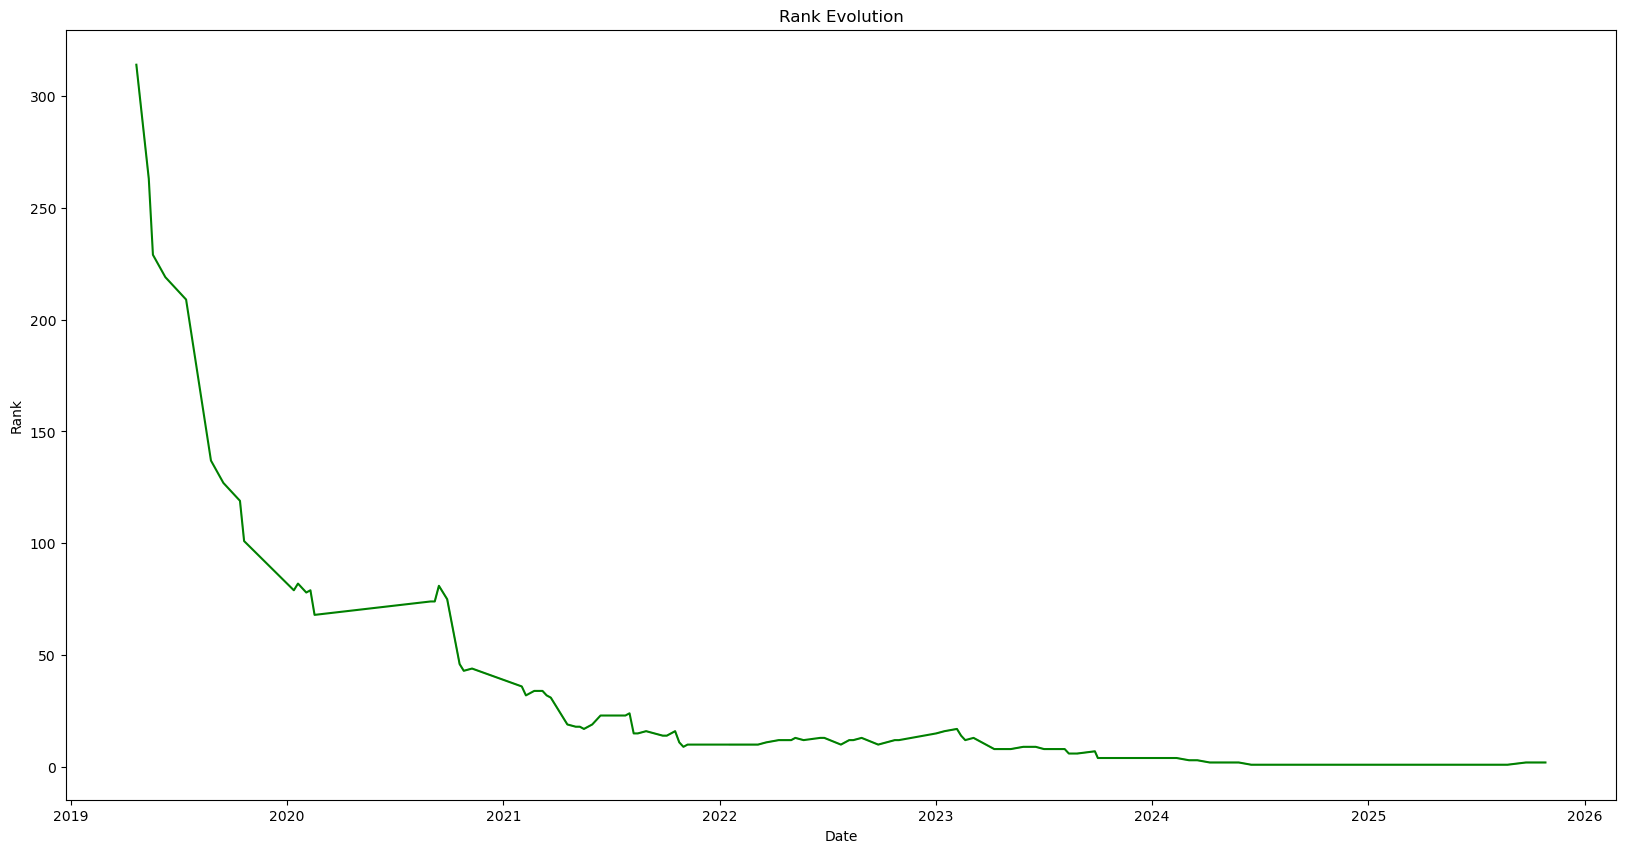

In [17]:
#Create a "Rank Evolution" plot
fig = plt.figure(figsize = (20,10))

ax = sns.lineplot(x = 'Date', y = 'Rank', data = js_rank, color = 'green')
ax.set(title = 'Rank Evolution')

plt.show()

**Conclusion**: From April 2019 to January 2020, Jannik Sinner climbed 235 positions. In November 2021, he entered the TOP 10 of the ATP ranking.

### Show number of wins and calculate win percentage

In [18]:
#Create a dataset for analyzing match wins
js_win_round = js_win[['winner_name', 'tourney_date', 'draw_size', 'tourney_level', 'surface', 'round']]\
             .reset_index(drop=True)
js_win_round.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 292 entries, 0 to 291
Data columns (total 6 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   winner_name    292 non-null    object        
 1   tourney_date   292 non-null    datetime64[ns]
 2   draw_size      292 non-null    float64       
 3   tourney_level  292 non-null    object        
 4   surface        292 non-null    object        
 5   round          292 non-null    object        
dtypes: datetime64[ns](1), float64(1), object(4)
memory usage: 13.8+ KB


In [19]:
#Analyze match wins by tourney_level and round
js_win_level = js_win_round.groupby('tourney_level')['round'].value_counts().unstack(fill_value = 0)
js_win_level

round,F,QF,R128,R16,R32,R64,SF
tourney_level,,,,,,,
500,2,2,0,2,3,0,2
A,11,18,0,27,28,0,13
G,4,8,20,13,18,18,6
M,5,13,0,18,27,25,9


In [20]:
#Define custom colors for each surface type
surface_colors = {
    'Clay': '#F57F1D',      #Orange
    'Grass': '#0AA84C',     #Green
    'Hard': '#33A7DD',      #Blue
}

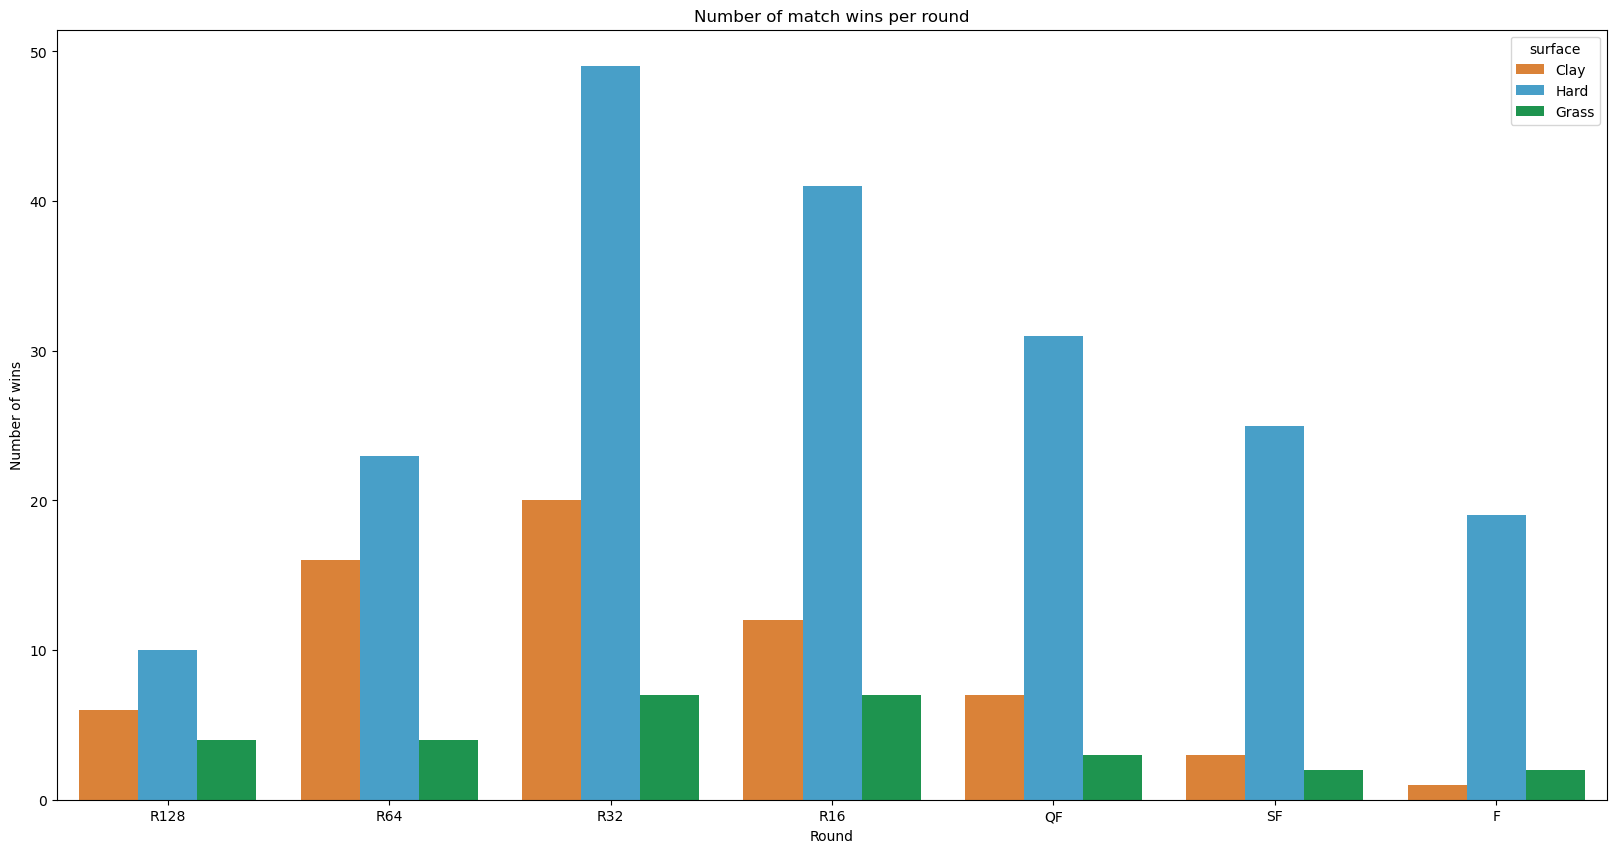

In [21]:
#Create a "Number of match wins" plot 
fig = plt.figure(figsize = (20,10))

round_order = ['R128', 'R64', 'R32', 'R16', 'QF', 'SF', 'F']
ax_1 = sns.countplot(data = js_win_round, x = 'round', hue = 'surface', order = round_order, \
                     palette = surface_colors)
ax_1.set(xlabel = 'Round', ylabel = 'Number of wins', title = 'Number of match wins per round')

plt.show()

In [22]:
#Create a dataset for analyzing match wins in ATP 250 and 500 level tournaments
js_win_round_a = js_win_round[(js_win_round.tourney_level == 'A')].reset_index(drop=True)
js_win_round_a

,winner_name,tourney_date,draw_size,tourney_level,surface,round
0,Jannik Sinner,2019-04-22,32.0,A,Clay,R32
1,Jannik Sinner,2019-07-15,32.0,A,Clay,R32
2,Jannik Sinner,2019-10-14,32.0,A,Hard,QF
3,Jannik Sinner,2019-10-14,32.0,A,Hard,R16
4,Jannik Sinner,2019-10-14,32.0,A,Hard,R32
...,...,...,...,...,...,...
92,Jannik Sinner,2024-06-17,32.0,A,Grass,R32
93,Jannik Sinner,2024-09-26,32.0,A,Hard,SF
94,Jannik Sinner,2024-09-26,32.0,A,Hard,QF
95,Jannik Sinner,2024-09-26,32.0,A,Hard,R16


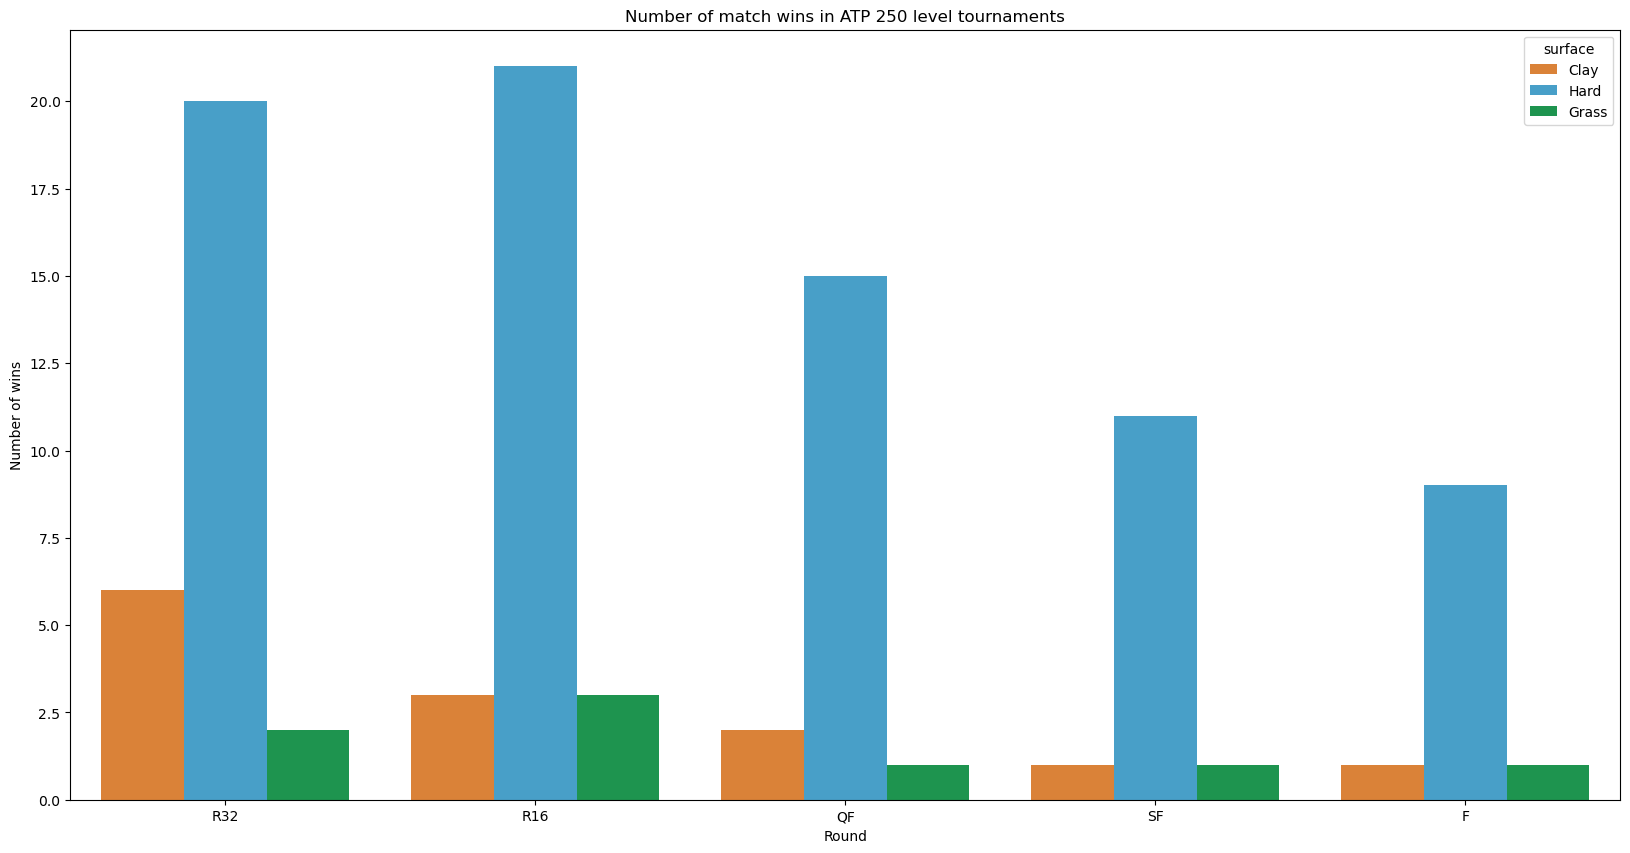

In [23]:
#Create a "Number of match wins in ATP 250 level tournaments" plot 
fig = plt.figure(figsize = (20,10))

ax_2 = sns.countplot(data = js_win_round_a, x = 'round', hue = 'surface', order = ['R32', 'R16', 'QF', 'SF', 'F'], \
                     palette = surface_colors)
ax_2.set(xlabel = 'Round', ylabel = 'Number of wins', title = 'Number of match wins in ATP 250 level tournaments')

plt.show()

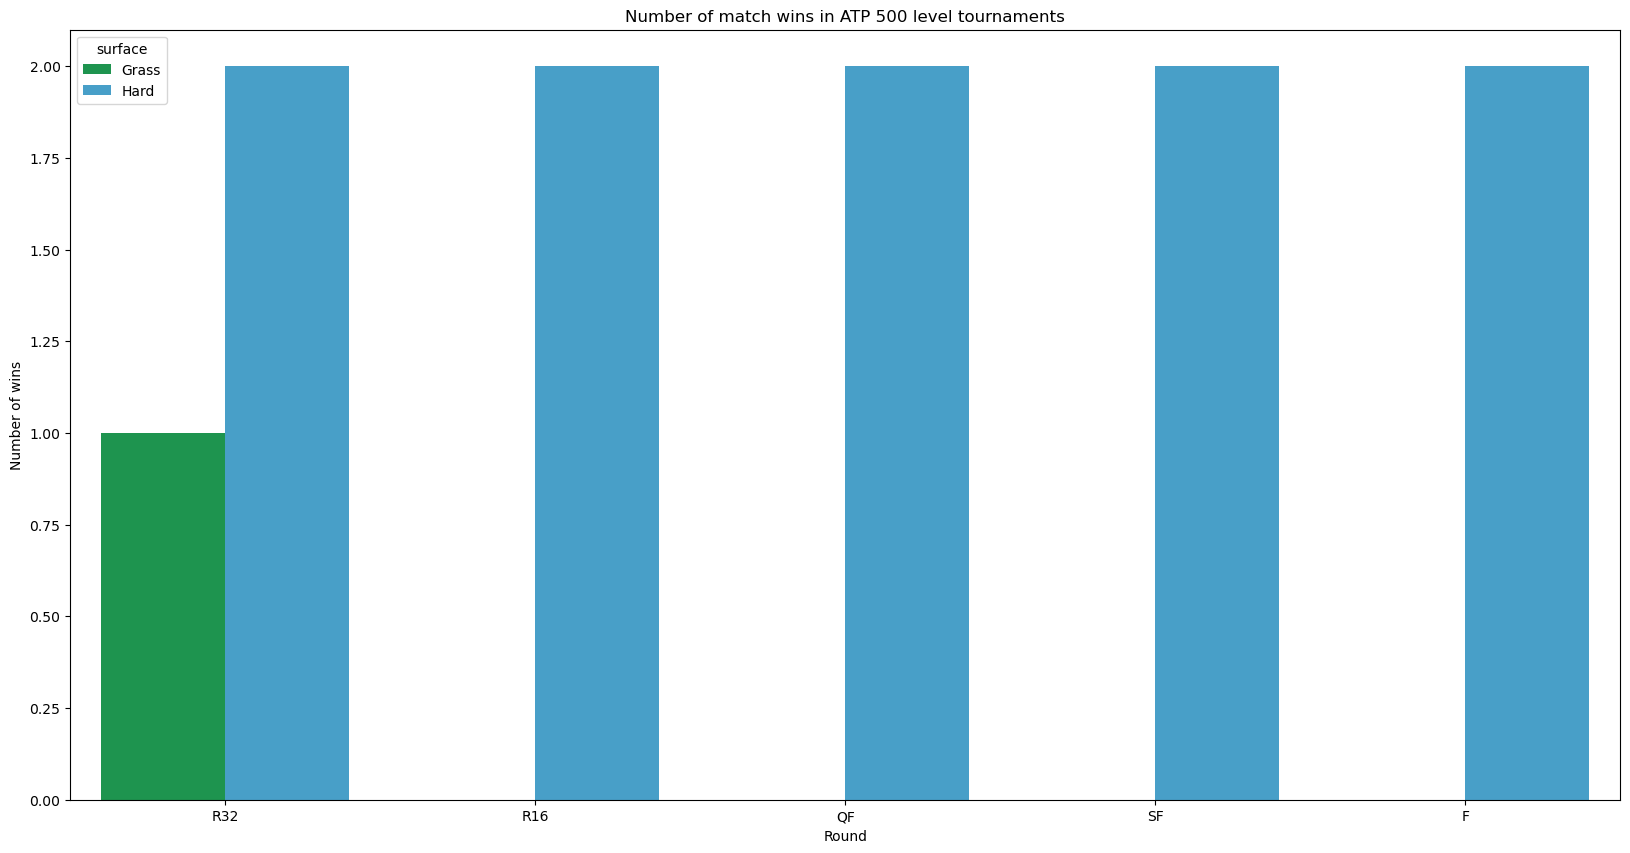

In [24]:
#Create a dataset for analyzing match wins in ATP 500 level tournaments
js_win_round_500 = js_win_round[(js_win_round.tourney_level == '500')].reset_index(drop=True)

#Create a "Number of match wins in ATP 500 level tournaments" plot 
fig = plt.figure(figsize = (20,10))

ax_3 = sns.countplot(data = js_win_round_500, x = 'round', hue = 'surface', order = ['R32', 'R16', 'QF', 'SF', 'F'], \
                     palette = surface_colors)
ax_3.set(xlabel = 'Round', ylabel = 'Number of wins', title = 'Number of match wins in ATP 500 level tournaments')


plt.show()

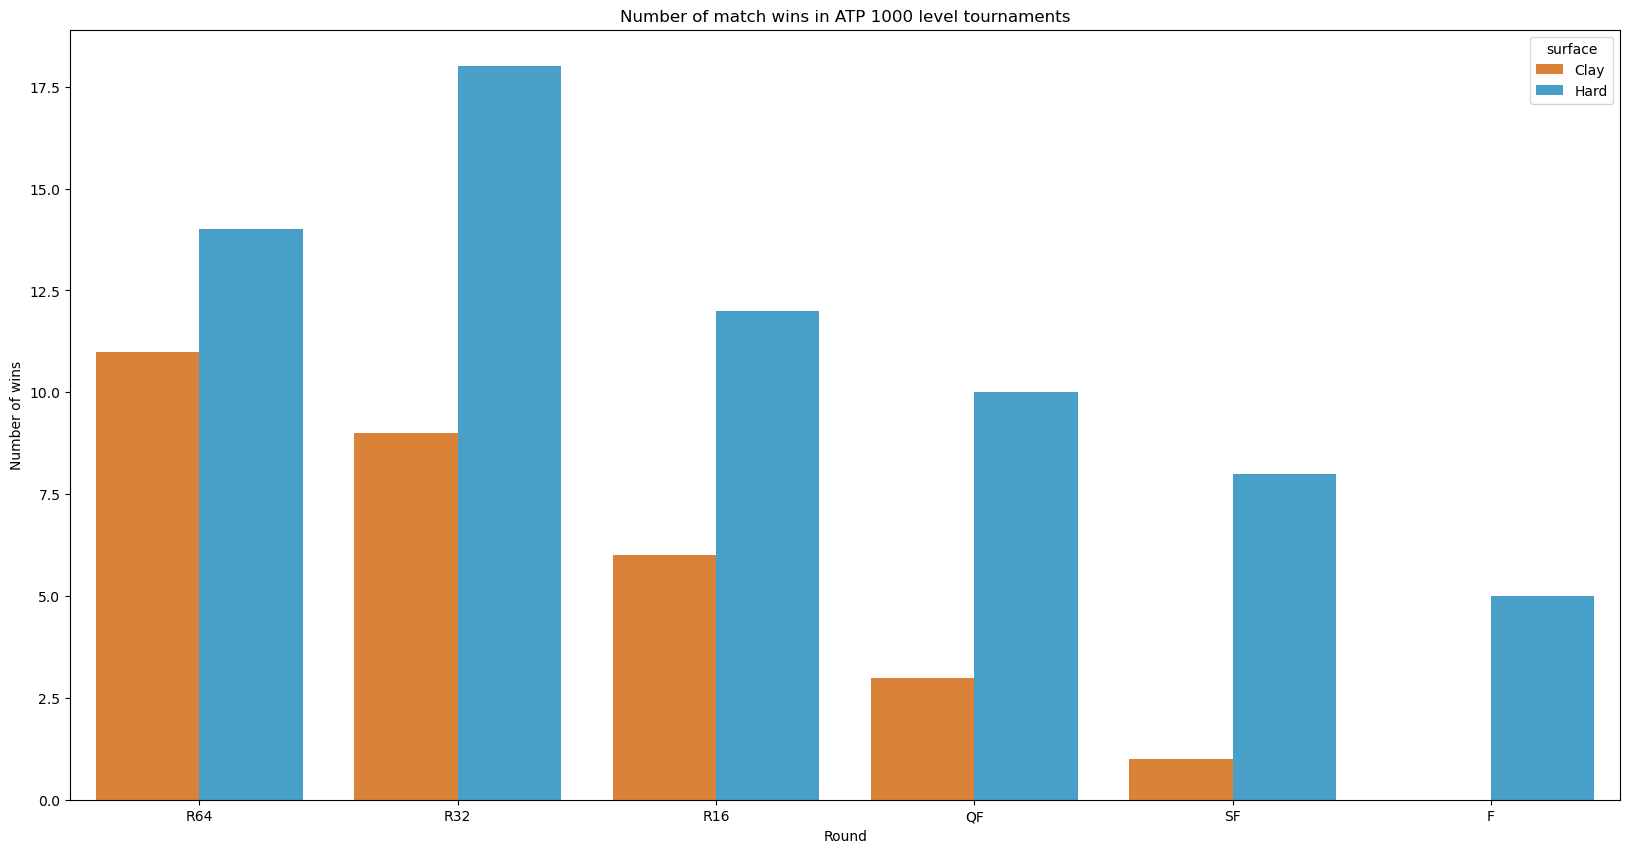

In [25]:
#Create a dataset for analyzing match wins in ATP 1000 level tournaments
js_win_round_m = js_win_round[(js_win_round.tourney_level == 'M')].reset_index(drop=True)

#Create a "Number of match wins in ATP 1000 level tournaments" plot 
fig = plt.figure(figsize = (20,10))

ax_4 = sns.countplot(data = js_win_round_m, x = 'round', hue = 'surface', \
                     order = ['R64', 'R32', 'R16', 'QF', 'SF', 'F'], palette = surface_colors)
ax_4.set(xlabel = 'Round', ylabel = 'Number of wins', title = 'Number of match wins in ATP 1000 level tournaments')


plt.show()

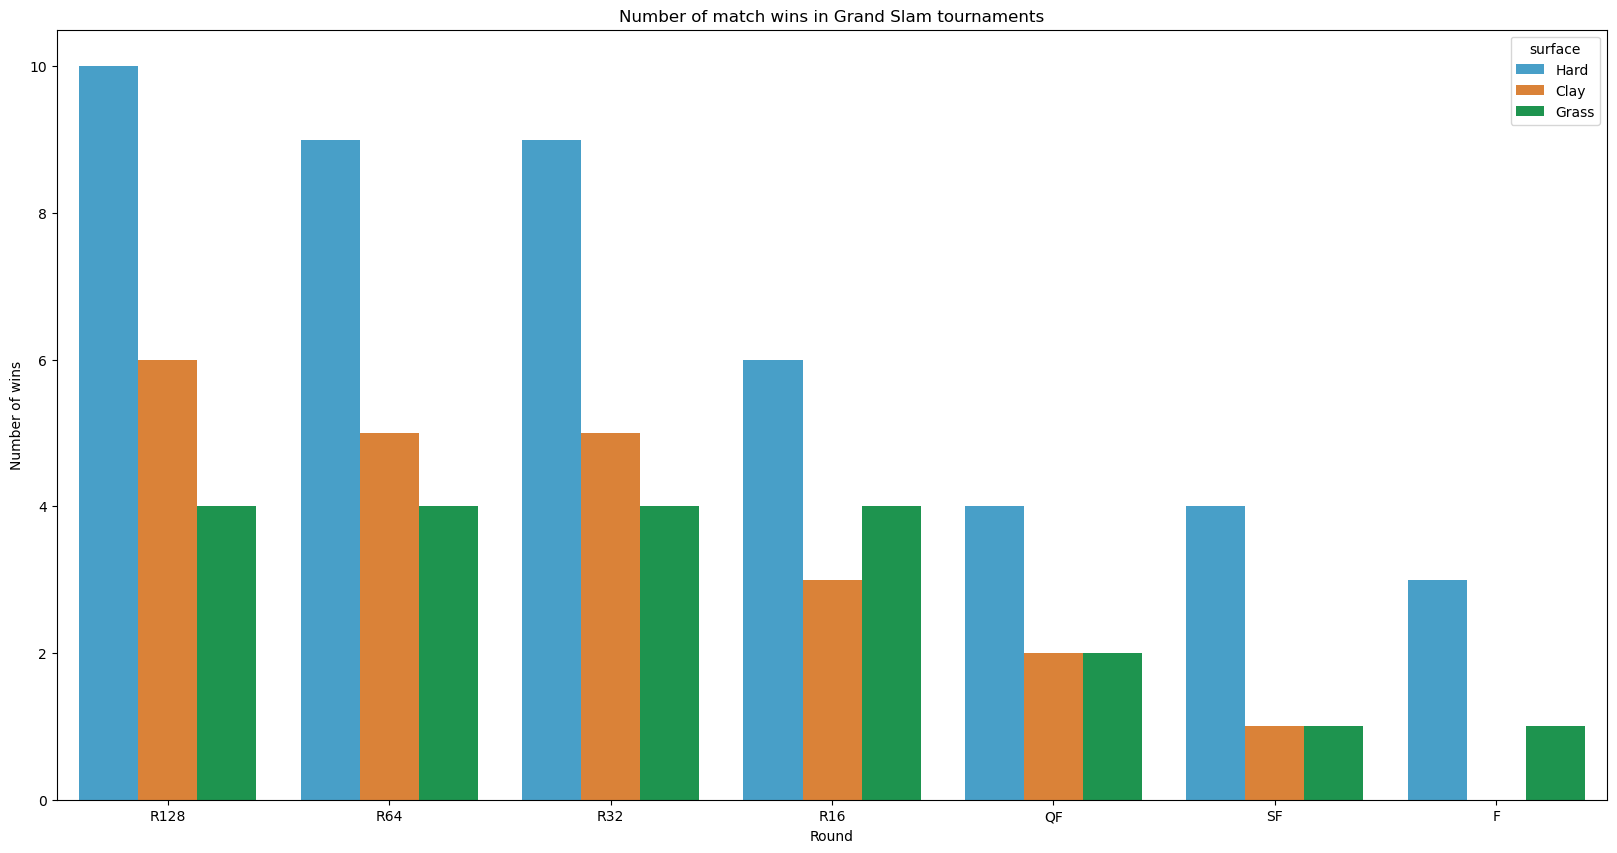

In [26]:
#Create a dataset for analyzing match wins in Grand Slam tournaments
js_win_round_g = js_win_round[(js_win_round.tourney_level == 'G')].reset_index(drop=True)

#Create a "Number of match wins in Grand Slam tournaments" plot 
fig = plt.figure(figsize = (20,10))

ax_5 = sns.countplot(data = js_win_round_g, x = 'round', hue = 'surface', order = round_order, \
                     palette = surface_colors)
ax_5.set(xlabel = 'Round', ylabel = 'Number of wins', title = 'Number of match wins in Grand Slam tournaments')

plt.show()

In [27]:
#Calculate the win percentage by surface
player_name = "Jannik Sinner"
surface = js_atp.groupby('surface').agg({
    'winner_name': [('total_matches', 'count'),
    ('wins', lambda x: (x == player_name).sum()),
    ('win_percentage', lambda x: (x == player_name).mean() * 100)]
}).round(1)
surface

winner_name                    
        total_matches wins win_percentage
surface                                  
Clay               91   65           71.4
Grass              39   29           74.4
Hard              249  198           79.5

**Conclusion**: Jannik Sinner has won 11 ATP 250 titles, 2 ATP 500 titles, 5 Masters titles, and 4 Grand Slam titles. His win percentage on hard court is 79.5%, 74.4% on grass, and 71.4% on clay.

### Analyze serve and return stats

In [28]:
#Create a dataset for analyzing winner's stats
js_win_stats = js_win[['winner_name', 'tourney_date', 'surface', 'w_ace', 'w_df', 'w_svpt', 'w_1stIn', \
                       'w_1stWon', 'w_2ndWon', 'w_SvGms', 'w_bpSaved', 'w_bpFaced']].reset_index(drop=True)
js_win_stats.head()

,winner_name,tourney_date,surface,w_ace,w_df,w_svpt,w_1stIn,w_1stWon,w_2ndWon,w_SvGms,w_bpSaved,w_bpFaced
0,Jannik Sinner,2019-04-22,Clay,1.0,2.0,68.0,36.0,24.0,10.0,12.0,2.0,8.0
1,Jannik Sinner,2019-05-13,Clay,3.0,3.0,78.0,47.0,33.0,14.0,13.0,1.0,4.0
2,Jannik Sinner,2019-07-15,Clay,1.0,4.0,87.0,46.0,34.0,18.0,13.0,3.0,7.0
3,Jannik Sinner,2019-10-14,Hard,10.0,2.0,80.0,51.0,41.0,15.0,14.0,4.0,5.0
4,Jannik Sinner,2019-10-14,Hard,2.0,1.0,44.0,21.0,17.0,17.0,8.0,1.0,1.0


In [29]:
# Create an 'outcome' column. Mark 'Win' if Jannik Sinner is the winner, otherwise 'Loss'
js_win_stats['outcome'] = np.where(js_win_stats['winner_name'] == 'Jannik Sinner', 'Win', 'Loss')
js_win_stats.head()

,winner_name,tourney_date,surface,w_ace,w_df,w_svpt,w_1stIn,w_1stWon,w_2ndWon,w_SvGms,w_bpSaved,w_bpFaced,outcome
0,Jannik Sinner,2019-04-22,Clay,1.0,2.0,68.0,36.0,24.0,10.0,12.0,2.0,8.0,Win
1,Jannik Sinner,2019-05-13,Clay,3.0,3.0,78.0,47.0,33.0,14.0,13.0,1.0,4.0,Win
2,Jannik Sinner,2019-07-15,Clay,1.0,4.0,87.0,46.0,34.0,18.0,13.0,3.0,7.0,Win
3,Jannik Sinner,2019-10-14,Hard,10.0,2.0,80.0,51.0,41.0,15.0,14.0,4.0,5.0,Win
4,Jannik Sinner,2019-10-14,Hard,2.0,1.0,44.0,21.0,17.0,17.0,8.0,1.0,1.0,Win


In [30]:
#Delete 'winner_name' column
js_win_stats = js_win_stats.drop('winner_name', axis = 1)

In [31]:
#Display information about a new dataframe
js_win_stats.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 292 entries, 0 to 291
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   tourney_date  292 non-null    datetime64[ns]
 1   surface       292 non-null    object        
 2   w_ace         286 non-null    float64       
 3   w_df          286 non-null    float64       
 4   w_svpt        286 non-null    float64       
 5   w_1stIn       286 non-null    float64       
 6   w_1stWon      286 non-null    float64       
 7   w_2ndWon      286 non-null    float64       
 8   w_SvGms       286 non-null    float64       
 9   w_bpSaved     286 non-null    float64       
 10  w_bpFaced     286 non-null    float64       
 11  outcome       292 non-null    object        
dtypes: datetime64[ns](1), float64(9), object(2)
memory usage: 27.5+ KB


In [32]:
#Set column headers
js_win_stats.columns = ['tourney_date', 'surface', 'ace', 'df', 'svpt', '1stIn', '1stWon', '2ndWon', \
                        'SvGms', 'bpSaved', 'bpFaced', 'outcome']
js_win_stats

,tourney_date,surface,ace,df,svpt,1stIn,1stWon,2ndWon,SvGms,bpSaved,bpFaced,outcome
0,2019-04-22,Clay,1.0,2.0,68.0,36.0,24.0,10.0,12.0,2.0,8.0,Win
1,2019-05-13,Clay,3.0,3.0,78.0,47.0,33.0,14.0,13.0,1.0,4.0,Win
2,2019-07-15,Clay,1.0,4.0,87.0,46.0,34.0,18.0,13.0,3.0,7.0,Win
3,2019-10-14,Hard,10.0,2.0,80.0,51.0,41.0,15.0,14.0,4.0,5.0,Win
4,2019-10-14,Hard,2.0,1.0,44.0,21.0,17.0,17.0,8.0,1.0,1.0,Win
...,...,...,...,...,...,...,...,...,...,...,...,...
287,2025-10-27,Hard,0.0,2.0,48.0,31.0,24.0,12.0,9.0,0.0,0.0,Win
288,2025-10-27,Hard,4.0,2.0,49.0,35.0,29.0,6.0,10.0,1.0,3.0,Win
289,2025-10-27,Hard,4.0,0.0,40.0,30.0,24.0,8.0,9.0,0.0,1.0,Win
290,2025-10-27,Hard,8.0,0.0,31.0,21.0,19.0,5.0,6.0,0.0,0.0,Win


In [33]:
#Calculate return points won percentage when Jannik Sinner is a winner of the match
js_win_stats['rp_pct'] = ((js_win['l_svpt'] - (js_win['l_1stWon'] + js_win['l_2ndWon'])) / js_win['l_svpt']).round(2)
js_win_stats.head()

,tourney_date,surface,ace,df,svpt,1stIn,1stWon,2ndWon,SvGms,bpSaved,bpFaced,outcome,rp_pct
0,2019-04-22,Clay,1.0,2.0,68.0,36.0,24.0,10.0,12.0,2.0,8.0,Win,0.49
1,2019-05-13,Clay,3.0,3.0,78.0,47.0,33.0,14.0,13.0,1.0,4.0,Win,0.38
2,2019-07-15,Clay,1.0,4.0,87.0,46.0,34.0,18.0,13.0,3.0,7.0,Win,0.37
3,2019-10-14,Hard,10.0,2.0,80.0,51.0,41.0,15.0,14.0,4.0,5.0,Win,0.33
4,2019-10-14,Hard,2.0,1.0,44.0,21.0,17.0,17.0,8.0,1.0,1.0,Win,0.47


In [34]:
#Calculate break points converted when Jannik Sinner is a winner of the match
js_win_stats['bp_won_pct'] = ((js_win['l_bpFaced'] - js_win['l_bpSaved']) / js_win['l_bpFaced']).round(2)
js_win_stats.head()

,tourney_date,surface,ace,df,svpt,1stIn,1stWon,2ndWon,SvGms,bpSaved,bpFaced,outcome,rp_pct,bp_won_pct
0,2019-04-22,Clay,1.0,2.0,68.0,36.0,24.0,10.0,12.0,2.0,8.0,Win,0.49,0.40
1,2019-05-13,Clay,3.0,3.0,78.0,47.0,33.0,14.0,13.0,1.0,4.0,Win,0.38,0.57
2,2019-07-15,Clay,1.0,4.0,87.0,46.0,34.0,18.0,13.0,3.0,7.0,Win,0.37,0.67
3,2019-10-14,Hard,10.0,2.0,80.0,51.0,41.0,15.0,14.0,4.0,5.0,Win,0.33,0.40
4,2019-10-14,Hard,2.0,1.0,44.0,21.0,17.0,17.0,8.0,1.0,1.0,Win,0.47,0.40


In [35]:
#Create a dataset for analyzing loser's stats
js_loss_stats = js_loss[['loser_name', 'tourney_date', 'surface', 'l_ace', 'l_df', 'l_svpt', \
                         'l_1stIn', 'l_1stWon', 'l_2ndWon', 'l_SvGms', 'l_bpSaved', 'l_bpFaced']] \
                .reset_index(drop=True)

# Create an 'outcome' column. Mark 'Loss' if Jannik Sinner is the loser, otherwise 'Win'
js_loss_stats['outcome'] = np.where(js_loss_stats['loser_name'] == 'Jannik Sinner', 'Loss', 'Win')

#Delete 'loser_name' column
js_loss_stats = js_loss_stats.drop('loser_name', axis = 1)

#Set column headers
js_loss_stats.columns = ['tourney_date', 'surface', 'ace', 'df', 'svpt', '1stIn', '1stWon', '2ndWon', \
                         'SvGms', 'bpSaved', 'bpFaced', 'outcome']
js_loss_stats

,tourney_date,surface,ace,df,svpt,1stIn,1stWon,2ndWon,SvGms,bpSaved,bpFaced,outcome
0,2019-04-22,Clay,1.0,1.0,70.0,38.0,20.0,16.0,8.0,5.0,9.0,Loss
1,2019-05-13,Clay,1.0,0.0,48.0,28.0,16.0,7.0,8.0,2.0,6.0,Loss
2,2019-05-20,Clay,3.0,2.0,55.0,31.0,14.0,17.0,9.0,3.0,7.0,Loss
3,2019-06-10,Grass,1.0,2.0,58.0,35.0,20.0,15.0,10.0,0.0,3.0,Loss
4,2019-07-15,Clay,3.0,1.0,74.0,43.0,27.0,17.0,10.0,2.0,5.0,Loss
...,...,...,...,...,...,...,...,...,...,...,...,...
82,2025-05-26,Clay,8.0,0.0,191.0,103.0,72.0,44.0,28.0,7.0,14.0,Loss
83,2025-06-16,Grass,6.0,3.0,90.0,57.0,44.0,16.0,14.0,4.0,6.0,Loss
84,2025-08-07,Hard,1.0,2.0,16.0,8.0,4.0,0.0,3.0,3.0,6.0,Loss
85,2025-08-24,Hard,2.0,4.0,112.0,54.0,37.0,28.0,17.0,6.0,11.0,Loss


In [36]:
#Calculate return points won percentage when Jannik Sinner is a loser of the match
js_loss_stats['rp_pct'] = ((js_loss['w_svpt'] - (js_loss['w_1stWon'] + js_loss['w_2ndWon'])) / js_loss['w_svpt']).round(2)
js_loss_stats.head()

,tourney_date,surface,ace,df,svpt,1stIn,1stWon,2ndWon,SvGms,bpSaved,bpFaced,outcome,rp_pct
0,2019-04-22,Clay,1.0,1.0,70.0,38.0,20.0,16.0,8.0,5.0,9.0,Loss,0.36
1,2019-05-13,Clay,1.0,0.0,48.0,28.0,16.0,7.0,8.0,2.0,6.0,Loss,0.35
2,2019-05-20,Clay,3.0,2.0,55.0,31.0,14.0,17.0,9.0,3.0,7.0,Loss,0.33
3,2019-06-10,Grass,1.0,2.0,58.0,35.0,20.0,15.0,10.0,0.0,3.0,Loss,0.33
4,2019-07-15,Clay,3.0,1.0,74.0,43.0,27.0,17.0,10.0,2.0,5.0,Loss,0.32


In [37]:
#Calculate break points converted when Jannik Sinner is a loser of the match
js_loss_stats['bp_won_pct'] = ((js_loss['w_bpFaced'] - js_loss['w_bpSaved']) / js_loss['w_bpFaced']).round(2)
js_loss_stats.head()

,tourney_date,surface,ace,df,svpt,1stIn,1stWon,2ndWon,SvGms,bpSaved,bpFaced,outcome,rp_pct,bp_won_pct
0,2019-04-22,Clay,1.0,1.0,70.0,38.0,20.0,16.0,8.0,5.0,9.0,Loss,0.36,0.00
1,2019-05-13,Clay,1.0,0.0,48.0,28.0,16.0,7.0,8.0,2.0,6.0,Loss,0.35,0.33
2,2019-05-20,Clay,3.0,2.0,55.0,31.0,14.0,17.0,9.0,3.0,7.0,Loss,0.33,0.20
3,2019-06-10,Grass,1.0,2.0,58.0,35.0,20.0,15.0,10.0,0.0,3.0,Loss,0.33,0.67
4,2019-07-15,Clay,3.0,1.0,74.0,43.0,27.0,17.0,10.0,2.0,5.0,Loss,0.32,0.33


In [38]:
#Combine 2 datasets into one dataset 'js_stats'
js_stats = pd.concat([js_win_stats, js_loss_stats], sort = False)
js_stats

,tourney_date,surface,ace,df,svpt,1stIn,1stWon,2ndWon,SvGms,bpSaved,bpFaced,outcome,rp_pct,bp_won_pct
0,2019-04-22,Clay,1.0,2.0,68.0,36.0,24.0,10.0,12.0,2.0,8.0,Win,0.49,0.40
1,2019-05-13,Clay,3.0,3.0,78.0,47.0,33.0,14.0,13.0,1.0,4.0,Win,0.38,0.57
2,2019-07-15,Clay,1.0,4.0,87.0,46.0,34.0,18.0,13.0,3.0,7.0,Win,0.37,0.67
3,2019-10-14,Hard,10.0,2.0,80.0,51.0,41.0,15.0,14.0,4.0,5.0,Win,0.33,0.40
4,2019-10-14,Hard,2.0,1.0,44.0,21.0,17.0,17.0,8.0,1.0,1.0,Win,0.47,0.40
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
82,2025-05-26,Clay,8.0,0.0,191.0,103.0,72.0,44.0,28.0,7.0,14.0,Loss,0.40,0.47
83,2025-06-16,Grass,6.0,3.0,90.0,57.0,44.0,16.0,14.0,4.0,6.0,Loss,0.32,0.11
84,2025-08-07,Hard,1.0,2.0,16.0,8.0,4.0,0.0,3.0,3.0,6.0,Loss,0.31,NaN
85,2025-08-24,Hard,2.0,4.0,112.0,54.0,37.0,28.0,17.0,6.0,11.0,Loss,0.28,1.00


In [39]:
#Display information about a new dataframe
js_stats.info()

<class 'pandas.core.frame.DataFrame'>
Index: 379 entries, 0 to 86
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   tourney_date  379 non-null    datetime64[ns]
 1   surface       379 non-null    object        
 2   ace           368 non-null    float64       
 3   df            368 non-null    float64       
 4   svpt          368 non-null    float64       
 5   1stIn         368 non-null    float64       
 6   1stWon        368 non-null    float64       
 7   2ndWon        368 non-null    float64       
 8   SvGms         368 non-null    float64       
 9   bpSaved       368 non-null    float64       
 10  bpFaced       368 non-null    float64       
 11  outcome       379 non-null    object        
 12  rp_pct        368 non-null    float64       
 13  bp_won_pct    359 non-null    float64       
dtypes: datetime64[ns](1), float64(11), object(2)
memory usage: 44.4+ KB


In [40]:
#Filter rows where 'bp_won_pct' column has missing (NaN) values
rows_with_nulls = js_stats[js_stats['bp_won_pct'].isnull()]
rows_with_nulls

,tourney_date,surface,ace,df,svpt,1stIn,1stWon,2ndWon,SvGms,bpSaved,bpFaced,outcome,rp_pct,bp_won_pct
9,2020-02-10,Hard,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Win,NaN,NaN
36,2021-10-04,Hard,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Win,NaN,NaN
43,2021-08-02,Hard,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Win,NaN,NaN
122,2023-02-06,Hard,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Win,NaN,NaN
155,2023-08-07,Hard,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Win,NaN,NaN
220,2024-08-12,Hard,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,Win,NaN,NaN
19,2020-10-26,Hard,0.0,0.0,11.0,8.0,5.0,1.0,2.0,0.0,1.0,Loss,0.00,NaN
39,2021-07-26,Hard,5.0,2.0,69.0,42.0,34.0,14.0,11.0,0.0,1.0,Loss,0.29,NaN
41,2022-01-17,Hard,4.0,1.0,66.0,42.0,30.0,13.0,13.0,0.0,4.0,Loss,0.27,NaN
42,2022-02-21,Hard,4.0,1.0,60.0,42.0,30.0,5.0,9.0,5.0,8.0,Loss,0.27,NaN


In [41]:
#Fill missing values in 'bp_won_pct' with 0 because Jannik Sinner didn't won break points
js_stats['bp_won_pct'] = js_stats['bp_won_pct'].fillna(0).round(2)
js_stats

,tourney_date,surface,ace,df,svpt,1stIn,1stWon,2ndWon,SvGms,bpSaved,bpFaced,outcome,rp_pct,bp_won_pct
0,2019-04-22,Clay,1.0,2.0,68.0,36.0,24.0,10.0,12.0,2.0,8.0,Win,0.49,0.40
1,2019-05-13,Clay,3.0,3.0,78.0,47.0,33.0,14.0,13.0,1.0,4.0,Win,0.38,0.57
2,2019-07-15,Clay,1.0,4.0,87.0,46.0,34.0,18.0,13.0,3.0,7.0,Win,0.37,0.67
3,2019-10-14,Hard,10.0,2.0,80.0,51.0,41.0,15.0,14.0,4.0,5.0,Win,0.33,0.40
4,2019-10-14,Hard,2.0,1.0,44.0,21.0,17.0,17.0,8.0,1.0,1.0,Win,0.47,0.40
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
82,2025-05-26,Clay,8.0,0.0,191.0,103.0,72.0,44.0,28.0,7.0,14.0,Loss,0.40,0.47
83,2025-06-16,Grass,6.0,3.0,90.0,57.0,44.0,16.0,14.0,4.0,6.0,Loss,0.32,0.11
84,2025-08-07,Hard,1.0,2.0,16.0,8.0,4.0,0.0,3.0,3.0,6.0,Loss,0.31,0.00
85,2025-08-24,Hard,2.0,4.0,112.0,54.0,37.0,28.0,17.0,6.0,11.0,Loss,0.28,1.00


In [42]:
#Display information about dataframe js_stats
js_stats.info()

<class 'pandas.core.frame.DataFrame'>
Index: 379 entries, 0 to 86
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   tourney_date  379 non-null    datetime64[ns]
 1   surface       379 non-null    object        
 2   ace           368 non-null    float64       
 3   df            368 non-null    float64       
 4   svpt          368 non-null    float64       
 5   1stIn         368 non-null    float64       
 6   1stWon        368 non-null    float64       
 7   2ndWon        368 non-null    float64       
 8   SvGms         368 non-null    float64       
 9   bpSaved       368 non-null    float64       
 10  bpFaced       368 non-null    float64       
 11  outcome       379 non-null    object        
 12  rp_pct        368 non-null    float64       
 13  bp_won_pct    379 non-null    float64       
dtypes: datetime64[ns](1), float64(11), object(2)
memory usage: 44.4+ KB


In [43]:
#Remove missing values
js_stats = js_stats.dropna()
js_stats.info()

<class 'pandas.core.frame.DataFrame'>
Index: 368 entries, 0 to 86
Data columns (total 14 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   tourney_date  368 non-null    datetime64[ns]
 1   surface       368 non-null    object        
 2   ace           368 non-null    float64       
 3   df            368 non-null    float64       
 4   svpt          368 non-null    float64       
 5   1stIn         368 non-null    float64       
 6   1stWon        368 non-null    float64       
 7   2ndWon        368 non-null    float64       
 8   SvGms         368 non-null    float64       
 9   bpSaved       368 non-null    float64       
 10  bpFaced       368 non-null    float64       
 11  outcome       368 non-null    object        
 12  rp_pct        368 non-null    float64       
 13  bp_won_pct    368 non-null    float64       
dtypes: datetime64[ns](1), float64(11), object(2)
memory usage: 43.1+ KB


In [44]:
#Convert 'ace' and 'df' to type 'int'
js_stats['ace'] = js_stats['ace'].astype(int)
js_stats['df'] = js_stats['df'].astype(int)

In [45]:
#Calculate ace rate, double fault rate, 1st serve percentage, 1st serve points won percentage, 2nd serve points won percentage
js_stats['pct_ace'] = (js_stats['ace'] / js_stats['svpt']).round(2)
js_stats['pct_df'] = (js_stats['df'] / js_stats['svpt']).round(2)
js_stats['pct_1stIn'] = (js_stats['1stIn'] / js_stats['svpt']).round(2)
js_stats['pct_1stWon'] = (js_stats['1stWon'] / js_stats['1stIn']).round(2)
js_stats['pct_2ndWon'] = (js_stats['2ndWon'] / (js_stats['svpt'] - js_stats['1stIn'])).round(2)
js_stats

,tourney_date,surface,ace,df,svpt,1stIn,1stWon,2ndWon,SvGms,bpSaved,bpFaced,outcome,rp_pct,bp_won_pct,pct_ace,pct_df,pct_1stIn,pct_1stWon,pct_2ndWon
0,2019-04-22,Clay,1,2,68.0,36.0,24.0,10.0,12.0,2.0,8.0,Win,0.49,0.40,0.01,0.03,0.53,0.67,0.31
1,2019-05-13,Clay,3,3,78.0,47.0,33.0,14.0,13.0,1.0,4.0,Win,0.38,0.57,0.04,0.04,0.60,0.70,0.45
2,2019-07-15,Clay,1,4,87.0,46.0,34.0,18.0,13.0,3.0,7.0,Win,0.37,0.67,0.01,0.05,0.53,0.74,0.44
3,2019-10-14,Hard,10,2,80.0,51.0,41.0,15.0,14.0,4.0,5.0,Win,0.33,0.40,0.12,0.02,0.64,0.80,0.52
4,2019-10-14,Hard,2,1,44.0,21.0,17.0,17.0,8.0,1.0,1.0,Win,0.47,0.40,0.05,0.02,0.48,0.81,0.74
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
82,2025-05-26,Clay,8,0,191.0,103.0,72.0,44.0,28.0,7.0,14.0,Loss,0.40,0.47,0.04,0.00,0.54,0.70,0.50
83,2025-06-16,Grass,6,3,90.0,57.0,44.0,16.0,14.0,4.0,6.0,Loss,0.32,0.11,0.07,0.03,0.63,0.77,0.48
84,2025-08-07,Hard,1,2,16.0,8.0,4.0,0.0,3.0,3.0,6.0,Loss,0.31,0.00,0.06,0.12,0.50,0.50,0.00
85,2025-08-24,Hard,2,4,112.0,54.0,37.0,28.0,17.0,6.0,11.0,Loss,0.28,1.00,0.02,0.04,0.48,0.69,0.48


In [46]:
#Calculate overall serve win percentage
js_stats['total_serve_win_pct'] = (js_stats['pct_1stIn'] * js_stats['pct_1stWon'] + (1 - js_stats['pct_1stIn']) \
                                   * js_stats['pct_2ndWon']).round(2)
js_stats

,tourney_date,surface,ace,df,svpt,1stIn,1stWon,2ndWon,SvGms,bpSaved,bpFaced,outcome,rp_pct,bp_won_pct,pct_ace,pct_df,pct_1stIn,pct_1stWon,pct_2ndWon,total_serve_win_pct
0,2019-04-22,Clay,1,2,68.0,36.0,24.0,10.0,12.0,2.0,8.0,Win,0.49,0.40,0.01,0.03,0.53,0.67,0.31,0.50
1,2019-05-13,Clay,3,3,78.0,47.0,33.0,14.0,13.0,1.0,4.0,Win,0.38,0.57,0.04,0.04,0.60,0.70,0.45,0.60
2,2019-07-15,Clay,1,4,87.0,46.0,34.0,18.0,13.0,3.0,7.0,Win,0.37,0.67,0.01,0.05,0.53,0.74,0.44,0.60
3,2019-10-14,Hard,10,2,80.0,51.0,41.0,15.0,14.0,4.0,5.0,Win,0.33,0.40,0.12,0.02,0.64,0.80,0.52,0.70
4,2019-10-14,Hard,2,1,44.0,21.0,17.0,17.0,8.0,1.0,1.0,Win,0.47,0.40,0.05,0.02,0.48,0.81,0.74,0.77
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
82,2025-05-26,Clay,8,0,191.0,103.0,72.0,44.0,28.0,7.0,14.0,Loss,0.40,0.47,0.04,0.00,0.54,0.70,0.50,0.61
83,2025-06-16,Grass,6,3,90.0,57.0,44.0,16.0,14.0,4.0,6.0,Loss,0.32,0.11,0.07,0.03,0.63,0.77,0.48,0.66
84,2025-08-07,Hard,1,2,16.0,8.0,4.0,0.0,3.0,3.0,6.0,Loss,0.31,0.00,0.06,0.12,0.50,0.50,0.00,0.25
85,2025-08-24,Hard,2,4,112.0,54.0,37.0,28.0,17.0,6.0,11.0,Loss,0.28,1.00,0.02,0.04,0.48,0.69,0.48,0.58


In [47]:
#Calculate ace to double fault ratio
js_stats['ace_to_df_ratio'] = js_stats['ace'] / js_stats['df']
js_stats

,tourney_date,surface,ace,df,svpt,1stIn,1stWon,2ndWon,SvGms,bpSaved,bpFaced,outcome,rp_pct,bp_won_pct,pct_ace,pct_df,pct_1stIn,pct_1stWon,pct_2ndWon,total_serve_win_pct,ace_to_df_ratio
0,2019-04-22,Clay,1,2,68.0,36.0,24.0,10.0,12.0,2.0,8.0,Win,0.49,0.40,0.01,0.03,0.53,0.67,0.31,0.50,0.50
1,2019-05-13,Clay,3,3,78.0,47.0,33.0,14.0,13.0,1.0,4.0,Win,0.38,0.57,0.04,0.04,0.60,0.70,0.45,0.60,1.00
2,2019-07-15,Clay,1,4,87.0,46.0,34.0,18.0,13.0,3.0,7.0,Win,0.37,0.67,0.01,0.05,0.53,0.74,0.44,0.60,0.25
3,2019-10-14,Hard,10,2,80.0,51.0,41.0,15.0,14.0,4.0,5.0,Win,0.33,0.40,0.12,0.02,0.64,0.80,0.52,0.70,5.00
4,2019-10-14,Hard,2,1,44.0,21.0,17.0,17.0,8.0,1.0,1.0,Win,0.47,0.40,0.05,0.02,0.48,0.81,0.74,0.77,2.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
82,2025-05-26,Clay,8,0,191.0,103.0,72.0,44.0,28.0,7.0,14.0,Loss,0.40,0.47,0.04,0.00,0.54,0.70,0.50,0.61,inf
83,2025-06-16,Grass,6,3,90.0,57.0,44.0,16.0,14.0,4.0,6.0,Loss,0.32,0.11,0.07,0.03,0.63,0.77,0.48,0.66,2.00
84,2025-08-07,Hard,1,2,16.0,8.0,4.0,0.0,3.0,3.0,6.0,Loss,0.31,0.00,0.06,0.12,0.50,0.50,0.00,0.25,0.50
85,2025-08-24,Hard,2,4,112.0,54.0,37.0,28.0,17.0,6.0,11.0,Loss,0.28,1.00,0.02,0.04,0.48,0.69,0.48,0.58,0.50


In [48]:
#Replace infinite values with zero
js_stats.replace([np.inf, -np.inf], 0, inplace = True)
js_stats

,tourney_date,surface,ace,df,svpt,1stIn,1stWon,2ndWon,SvGms,bpSaved,bpFaced,outcome,rp_pct,bp_won_pct,pct_ace,pct_df,pct_1stIn,pct_1stWon,pct_2ndWon,total_serve_win_pct,ace_to_df_ratio
0,2019-04-22,Clay,1,2,68.0,36.0,24.0,10.0,12.0,2.0,8.0,Win,0.49,0.40,0.01,0.03,0.53,0.67,0.31,0.50,0.50
1,2019-05-13,Clay,3,3,78.0,47.0,33.0,14.0,13.0,1.0,4.0,Win,0.38,0.57,0.04,0.04,0.60,0.70,0.45,0.60,1.00
2,2019-07-15,Clay,1,4,87.0,46.0,34.0,18.0,13.0,3.0,7.0,Win,0.37,0.67,0.01,0.05,0.53,0.74,0.44,0.60,0.25
3,2019-10-14,Hard,10,2,80.0,51.0,41.0,15.0,14.0,4.0,5.0,Win,0.33,0.40,0.12,0.02,0.64,0.80,0.52,0.70,5.00
4,2019-10-14,Hard,2,1,44.0,21.0,17.0,17.0,8.0,1.0,1.0,Win,0.47,0.40,0.05,0.02,0.48,0.81,0.74,0.77,2.00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
82,2025-05-26,Clay,8,0,191.0,103.0,72.0,44.0,28.0,7.0,14.0,Loss,0.40,0.47,0.04,0.00,0.54,0.70,0.50,0.61,0.00
83,2025-06-16,Grass,6,3,90.0,57.0,44.0,16.0,14.0,4.0,6.0,Loss,0.32,0.11,0.07,0.03,0.63,0.77,0.48,0.66,2.00
84,2025-08-07,Hard,1,2,16.0,8.0,4.0,0.0,3.0,3.0,6.0,Loss,0.31,0.00,0.06,0.12,0.50,0.50,0.00,0.25,0.50
85,2025-08-24,Hard,2,4,112.0,54.0,37.0,28.0,17.0,6.0,11.0,Loss,0.28,1.00,0.02,0.04,0.48,0.69,0.48,0.58,0.50


In [49]:
#Analyze serve stats by outcome
stats_by_outcome = js_stats.groupby('outcome')[['ace', 'df', 'pct_1stIn', 'pct_1stWon', 'pct_2ndWon', \
                                               'total_serve_win_pct']].mean().round(2)
stats_by_outcome.rename(columns = {'ace': 'ace_avg', 'df': 'df_avg', 'pct_1stIn': 'pct_1stIn_avg', \
                                 'pct_1stWon': 'pct_1stWon_avg', 'pct_2ndWon': 'pct_2ndWon_avg', \
                                 'total_serve_win_pct': 'total_serve_win_pct_avg'}, inplace = True)
stats_by_outcome

,ace_avg,df_avg,pct_1stIn_avg,pct_1stWon_avg,pct_2ndWon_avg,total_serve_win_pct_avg
outcome,,,,,,
Loss,4.41,2.61,0.59,0.67,0.47,0.59
Win,6.13,1.88,0.61,0.79,0.59,0.71


In [50]:
#Analyze serve stats by surface
stats_by_surface = js_stats.groupby('surface')[['ace', 'df', 'pct_1stIn', 'pct_1stWon', 'pct_2ndWon', \
                                               'total_serve_win_pct']].mean().round(2)
stats_by_surface.rename(columns = {'ace': 'ace_avg', 'df': 'df_avg', 'pct_1stIn': 'pct_1stIn_avg', \
                                 'pct_1stWon': 'pct_1stWon_avg', 'pct_2ndWon': 'pct_2ndWon_avg', \
                                 'total_serve_win_pct': 'total_serve_win_pct_avg'}, inplace = True)
stats_by_surface

,ace_avg,df_avg,pct_1stIn_avg,pct_1stWon_avg,pct_2ndWon_avg,total_serve_win_pct_avg
surface,,,,,,
Clay,3.61,1.88,0.60,0.72,0.55,0.65
Grass,8.72,2.49,0.61,0.79,0.59,0.71
Hard,6.05,2.03,0.60,0.77,0.56,0.69


In [51]:
#Analyze return points percentage by surface and compare with total serve win percentage
return_by_surface = js_stats.groupby('surface')[['rp_pct', 'total_serve_win_pct']].mean().round(2)
return_by_surface.rename(columns = {'rp_pct': 'rp_pct_avg', 'total_serve_win_pct': 'total_serve_win_pct_avg'}, \
                         inplace = True)
return_by_surface

,rp_pct_avg,total_serve_win_pct_avg
surface,,
Clay,0.43,0.65
Grass,0.38,0.71
Hard,0.41,0.69


In [52]:
#Filter to keep only 'Hard' and 'Clay' surfaces
surface_h_c = js_stats[js_stats['surface'].isin(['Hard', 'Clay'])]

#Define custom colors for 'Hard' and 'Clay' surfaces
colors = {
    'Clay': '#F57F1D',      #Orange
    'Hard': '#33A7DD',      #Blue
}

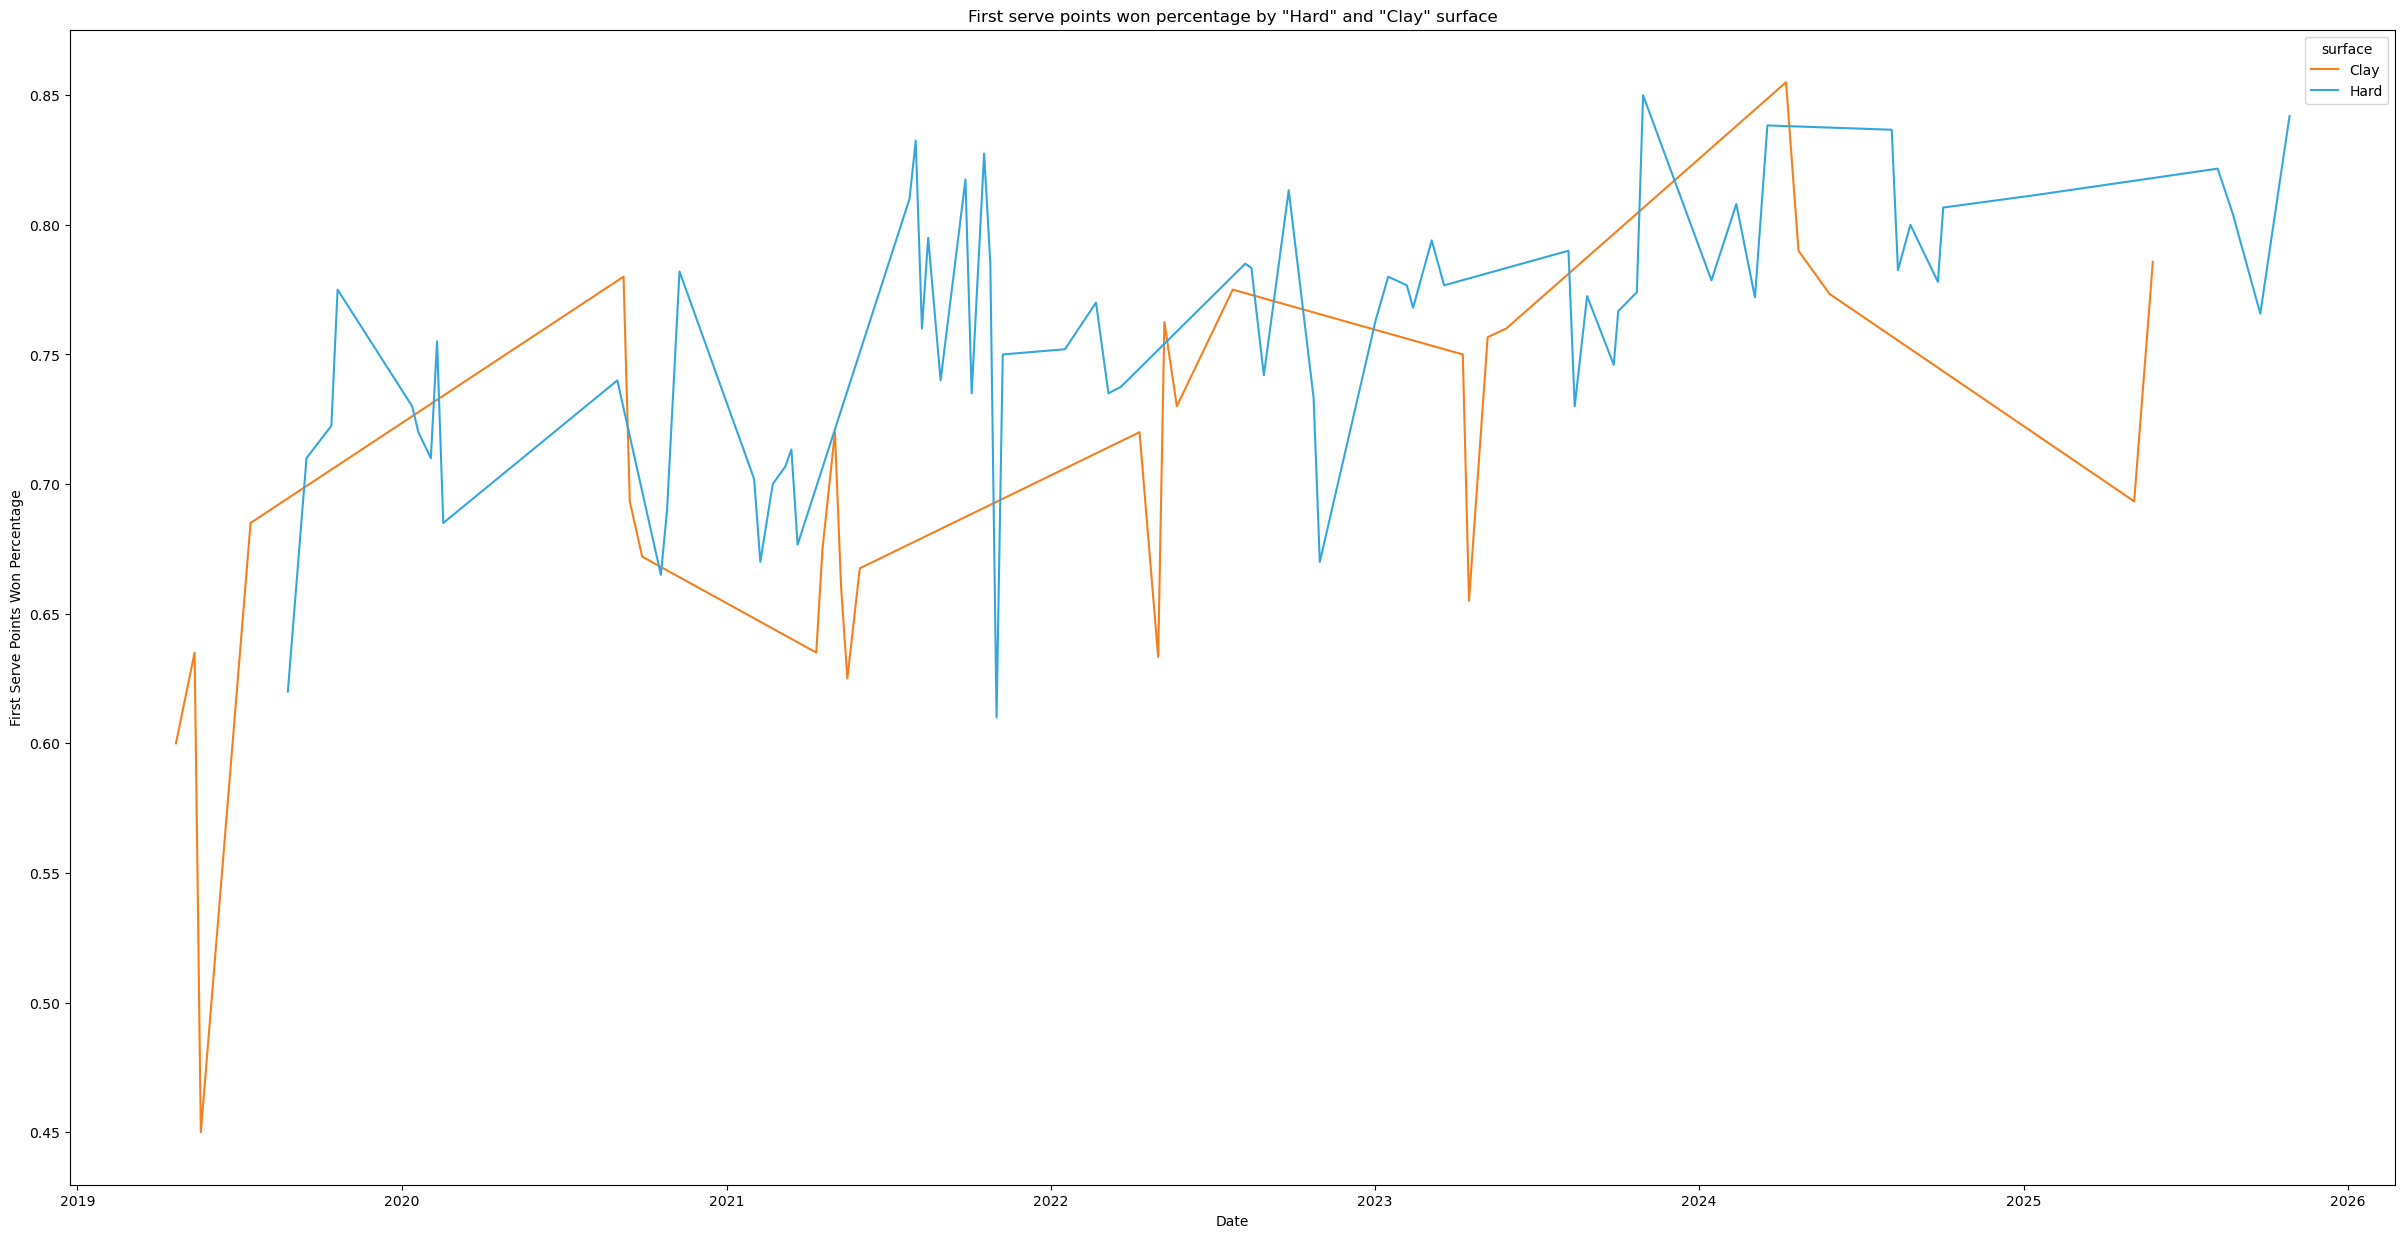

In [53]:
#Create a "First serve points won percentage by surface" plot 
fig = plt.figure(figsize = (30,15))

ax_6 = sns.lineplot(x = 'tourney_date', y = 'pct_1stWon', data = surface_h_c, errorbar = None, hue = 'surface', \
                   palette = colors)
ax_6.set(xlabel = 'Date', ylabel = 'First Serve Points Won Percentage', \
         title = 'First serve points won percentage by "Hard" and "Clay" surface')

plt.show()

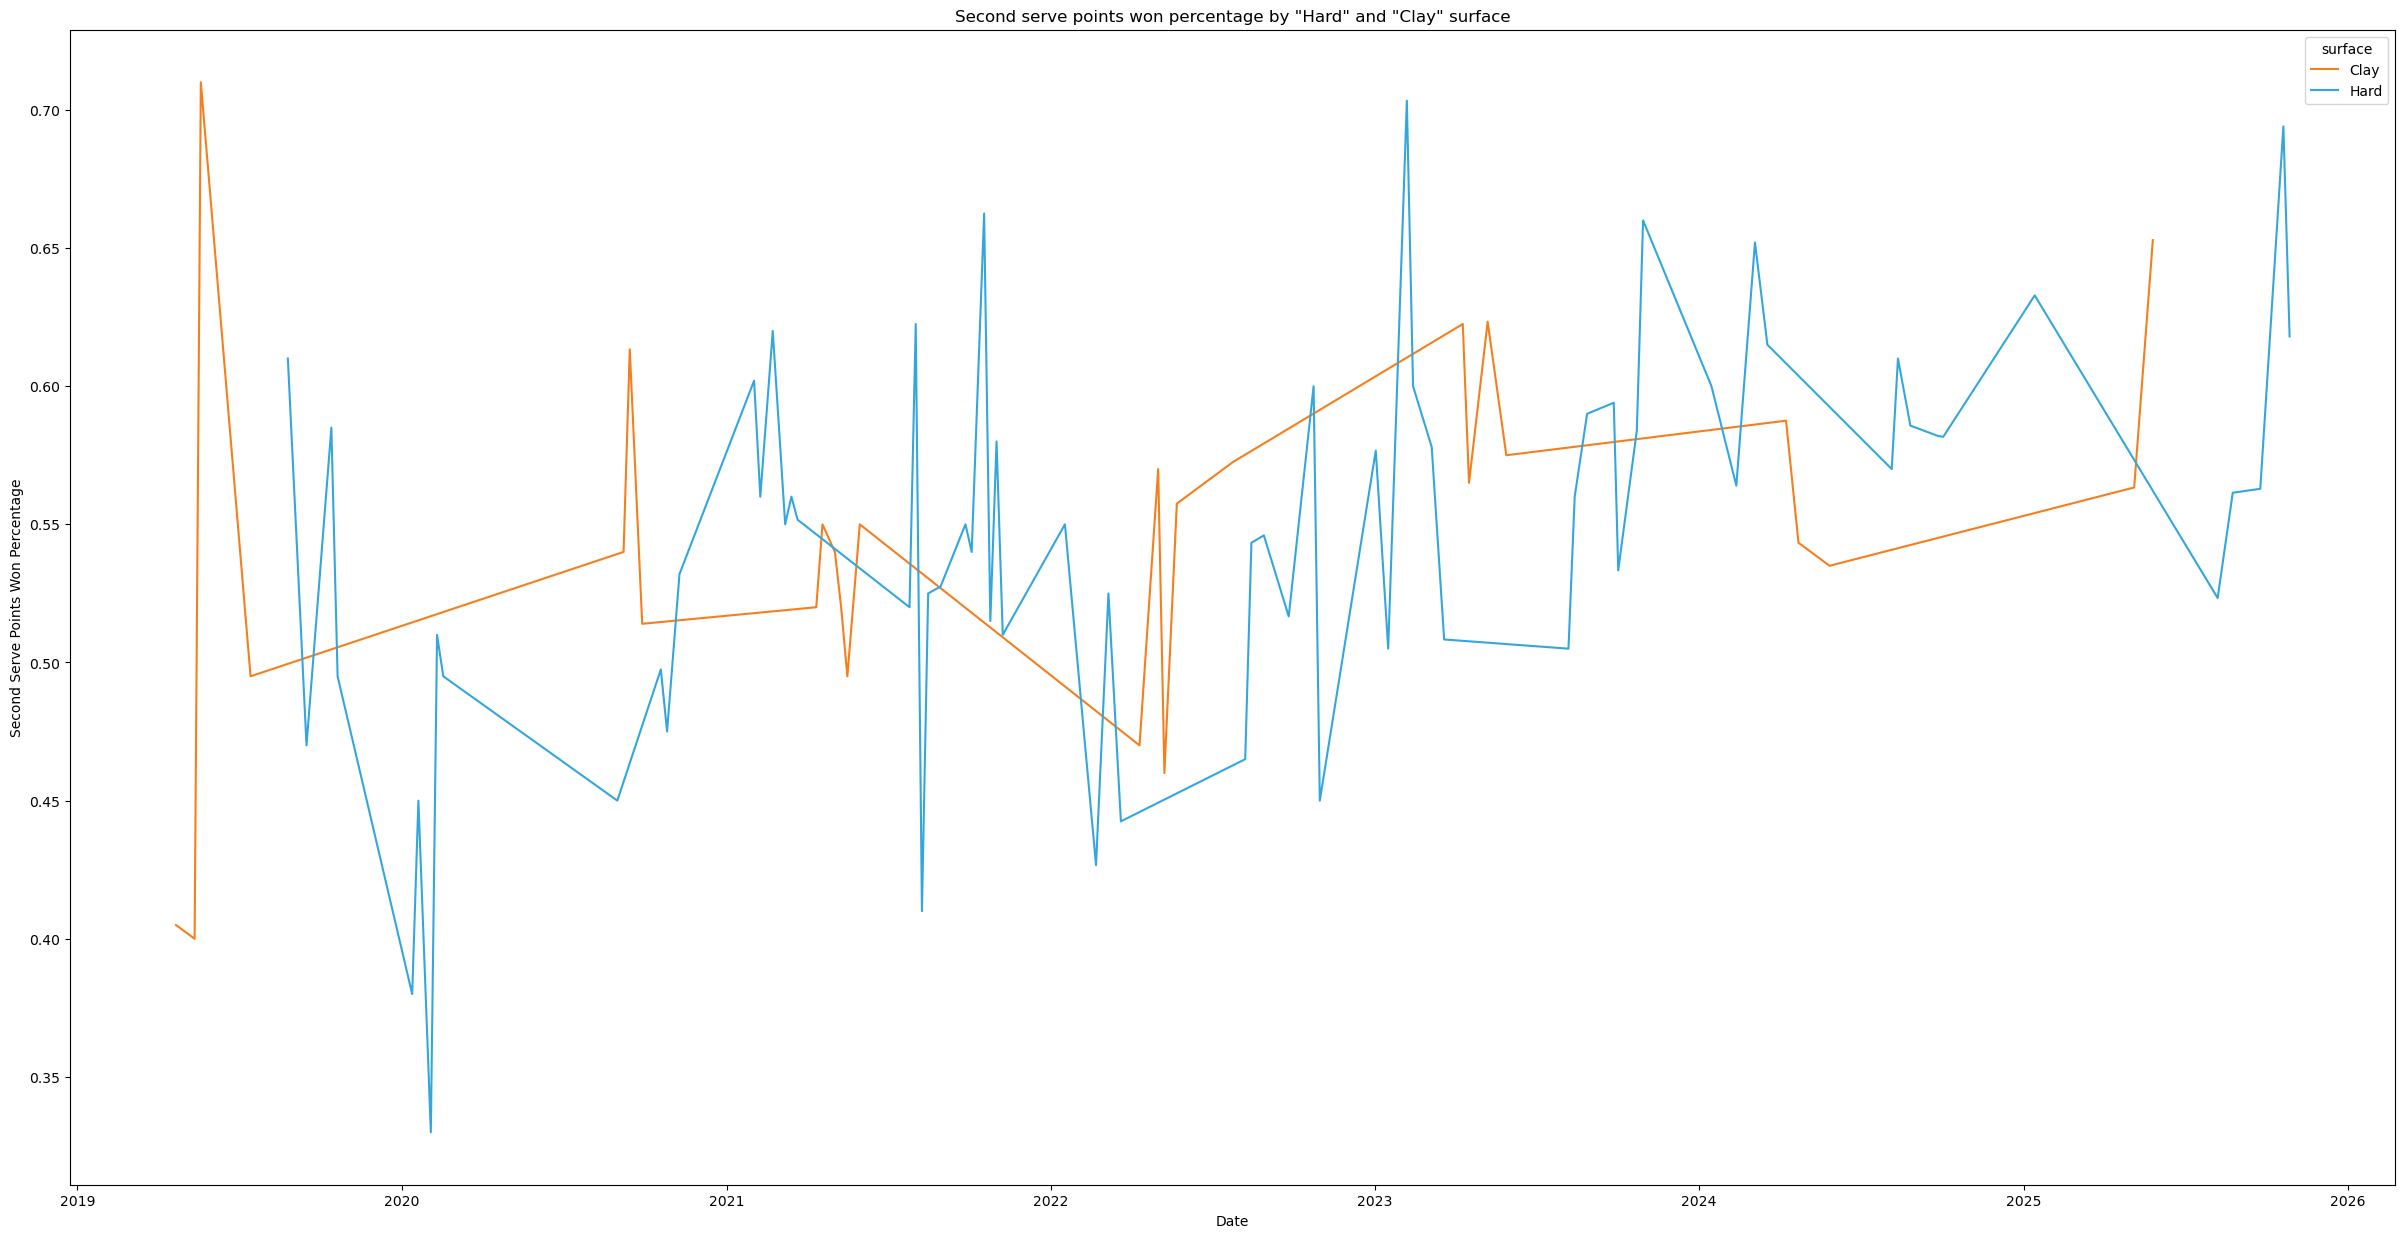

In [54]:
#Create a "Second serve points won percentage by surface" plot 
fig = plt.figure(figsize = (30,15))

ax_7 = sns.lineplot(x = 'tourney_date', y = 'pct_2ndWon', data = surface_h_c, errorbar = None, hue = 'surface', \
                   palette = colors)
ax_7.set(xlabel = 'Date', ylabel = 'Second Serve Points Won Percentage', \
         title = 'Second serve points won percentage by "Hard" and "Clay" surface')

plt.show()

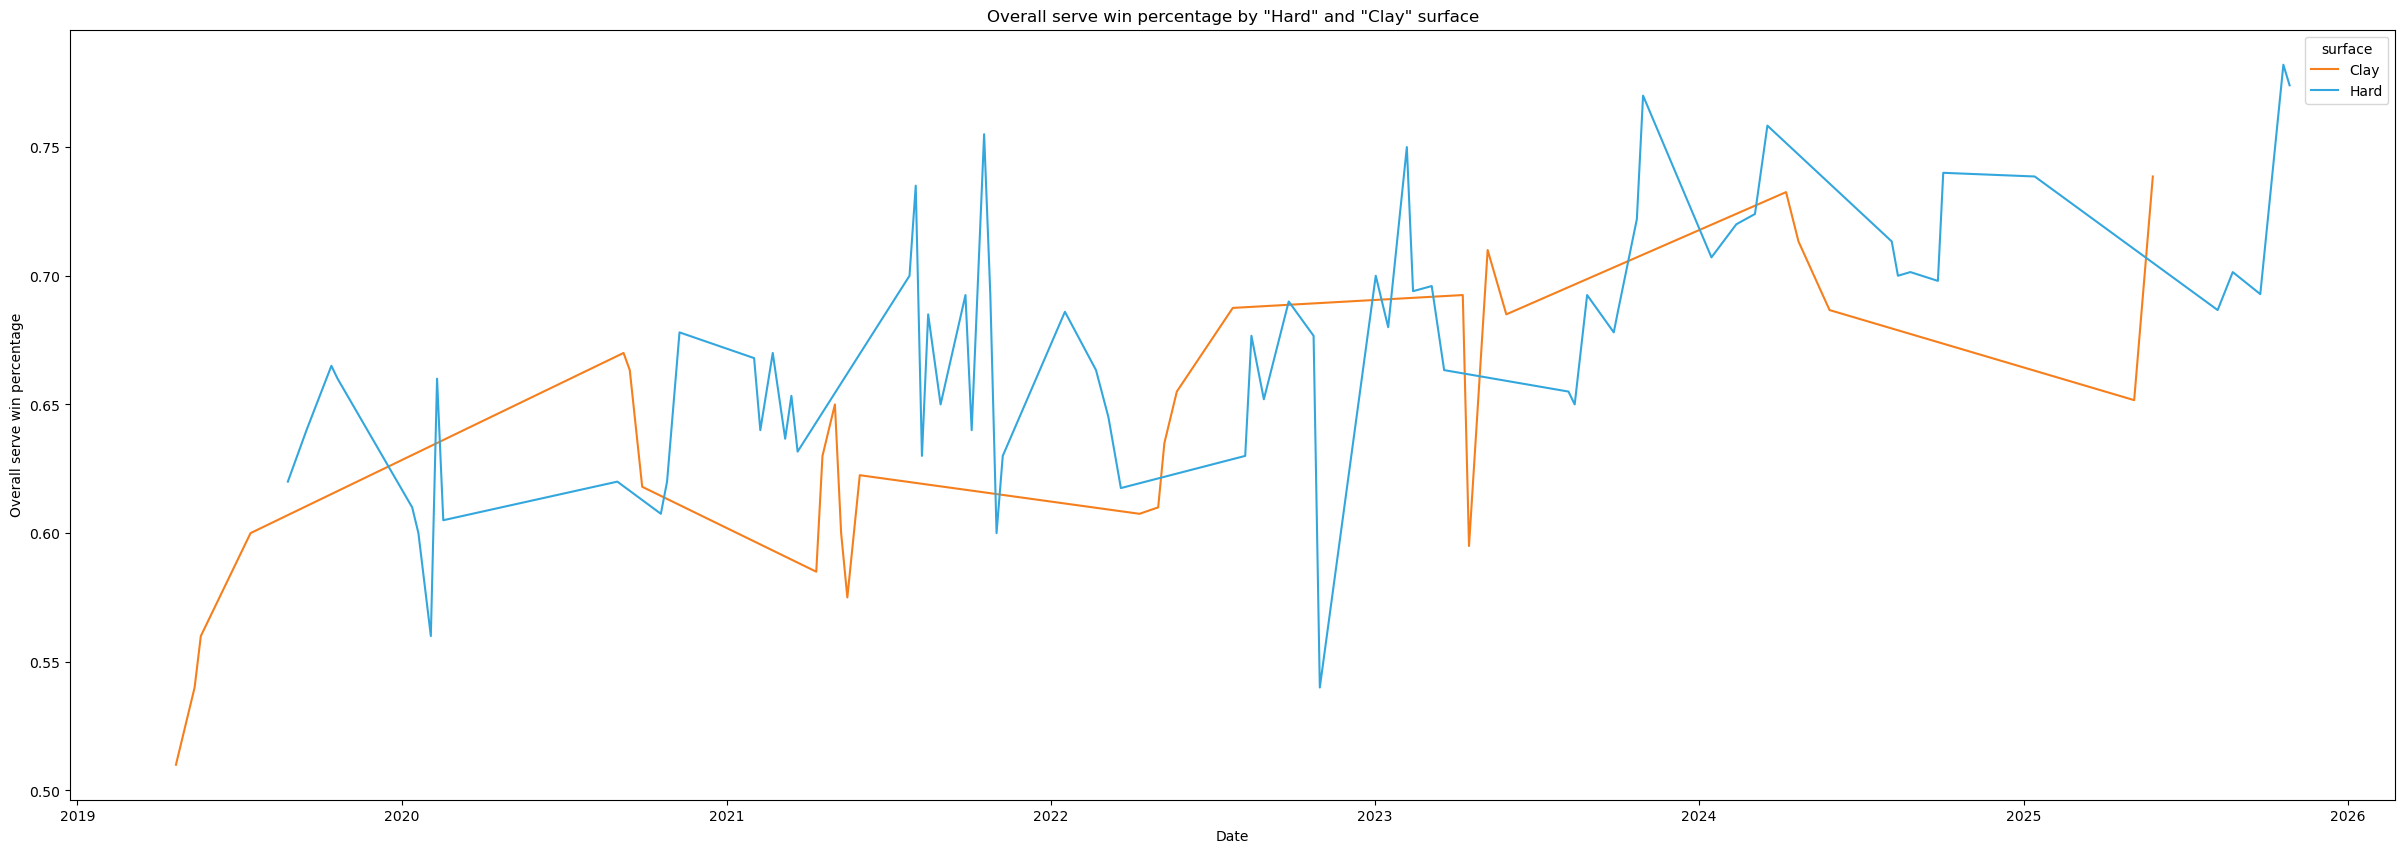

In [55]:
#Create a "Overall serve win percentage by surface" plot 
fig = plt.figure(figsize = (30,10))

ax_8 = sns.lineplot(x = 'tourney_date', y ='total_serve_win_pct', data = surface_h_c, errorbar = None, \
                    hue = 'surface', palette = colors)
ax_8.set(xlabel = 'Date', ylabel = 'Overall serve win percentage', \
         title = 'Overall serve win percentage by "Hard" and "Clay" surface')

plt.show()

In [56]:
# Create dataframe with average win percentage for 1st and 2nd serve points
serve_performance = pd.DataFrame({'serve_type': ['First Serve Points Won', 'Second Serve Points Won'], \
                                  'win_pct': [js_stats['pct_1stWon'].mean() * 100, \
                                              js_stats['pct_2ndWon'].mean() * 100]}).round(2)
serve_performance

,serve_type,win_pct
0,First Serve Points Won,76.01
1,Second Serve Points Won,56.24


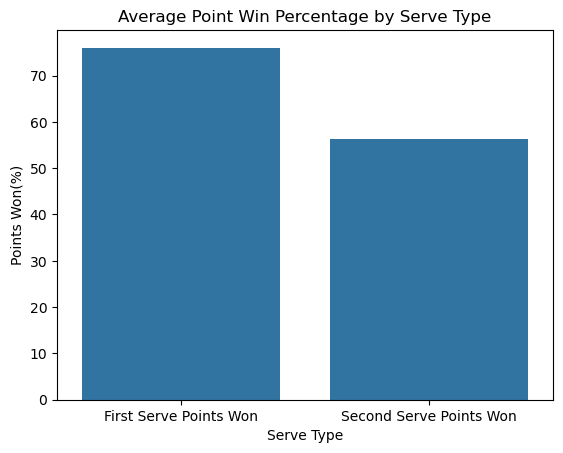

In [57]:
#Create a "Average Point Win Percentage by Serve Type" plot 
sns.barplot(x = 'serve_type', y = 'win_pct', data = serve_performance)
plt.xlabel('Serve Type')
plt.ylabel('Points Won(%)')
plt.title('Average Point Win Percentage by Serve Type')

plt.show()

In [58]:
#Calculate consistency (standard deviation) of serve metrics by surface
js_consistency = js_stats.groupby('surface')[['ace', 'pct_1stWon', 'pct_2ndWon']].std().round(2)
js_consistency.rename(columns = {'ace':'std_ace', 'pct_1stWon':'std_pct_1stWon', \
                               'pct_2ndWon':'std_pct_2ndWon'}, inplace = True)

js_consistency

,std_ace,std_pct_1stWon,std_pct_2ndWon
surface,,,
Clay,2.75,0.10,0.11
Grass,4.17,0.08,0.10
Hard,3.68,0.09,0.12


**Conclusion**: 
- Across all matches and surfaces, Jannik Sinner averages 76.01% of points won on first serve and 56.24% on second serve.

- In matches Sinner wins, he takes 12% more points on his own serve than in matches he loses: 79% vs 67% on first serve, 59% vs 47% on second serve. First serve percentage is nearly identical (61% vs 59%).

- Jannik Sinner's serve performance is highest on grass, followed by hard court, and lowest on clay. On grass, first serve points won is 79%, second serve points won is 59%, and total serve points won is 71%. On hard court serve performance metrics are 77%, 56%, and 69% respectively. On clay these metrics are 72%, 55%, and 65% respectively.

- Sinner's serve consistency is highest on grass (lowest standard deviation) for both 1st and 2nd serve points won (0.08 and 0.10 respectively), and least consistent on clay for 1st serve (0.10) and on hard court for 2nd serve (0.12).

- Grass surface shows the lowest return points won percentage (38%). Clay has the highest return points won (43%). Hard surface sits in the middle - 41% return points won percentage.

### Analyze stats of break points

In [59]:
#Create a dataset for analyzing break points
js_bp = js_stats[['surface', 'SvGms', 'svpt', 'bpSaved', 'bpFaced', 'bp_won_pct']].reset_index(drop=True)

# Calculate break points faced per game (as percentage) and break points saved percentage
js_bp['bp_faced_per_game'] = (js_bp['bpFaced'] / js_bp['SvGms'] * 100).round(2)
js_bp['bp_faced_pct'] = (js_bp['bpFaced'] / js_bp['svpt']).round(2)
js_bp['bp_saved_pct'] = (js_bp['bpSaved'] / js_bp['bpFaced']).round(2)
js_bp

,surface,SvGms,svpt,bpSaved,bpFaced,bp_won_pct,bp_faced_per_game,bp_faced_pct,bp_saved_pct
0,Clay,12.0,68.0,2.0,8.0,0.40,66.67,0.12,0.25
1,Clay,13.0,78.0,1.0,4.0,0.57,30.77,0.05,0.25
2,Clay,13.0,87.0,3.0,7.0,0.67,53.85,0.08,0.43
3,Hard,14.0,80.0,4.0,5.0,0.40,35.71,0.06,0.80
4,Hard,8.0,44.0,1.0,1.0,0.40,12.50,0.02,1.00
...,...,...,...,...,...,...,...,...,...
363,Clay,28.0,191.0,7.0,14.0,0.47,50.00,0.07,0.50
364,Grass,14.0,90.0,4.0,6.0,0.11,42.86,0.07,0.67
365,Hard,3.0,16.0,3.0,6.0,0.00,200.00,0.38,0.50
366,Hard,17.0,112.0,6.0,11.0,1.00,64.71,0.10,0.55


In [60]:
# Aggregate break point stats by surface
break_points_summary = js_bp.groupby('surface').agg({
    'SvGms': 'mean',
    'bpSaved': 'sum',
    'bpFaced': 'sum',
    'bp_faced_per_game': 'mean',
    'bp_faced_pct': 'mean',
    'bp_saved_pct': 'mean',
    'bp_won_pct': 'mean'
}).round(2)

#Set column headers
break_points_summary.columns = ['Avg_Games_Served', 'Total_BP_Saved', 'Total_BP_Faced', 'BP_Faced_Per_Game', \
                                'Avg_BP_Faced_%', 'Avg_BP_Saved_%', 'Avg_BP_Conv_%']
break_points_summary

,Avg_Games_Served,Total_BP_Saved,Total_BP_Faced,BP_Faced_Per_Game,Avg_BP_Faced_%,Avg_BP_Saved_%,Avg_BP_Conv_%
surface,,,,,,,
Clay,12.52,346.0,557.0,49.98,0.08,0.61,0.50
Grass,15.18,122.0,184.0,29.84,0.05,0.69,0.43
Hard,12.22,853.0,1241.0,40.92,0.06,0.67,0.45


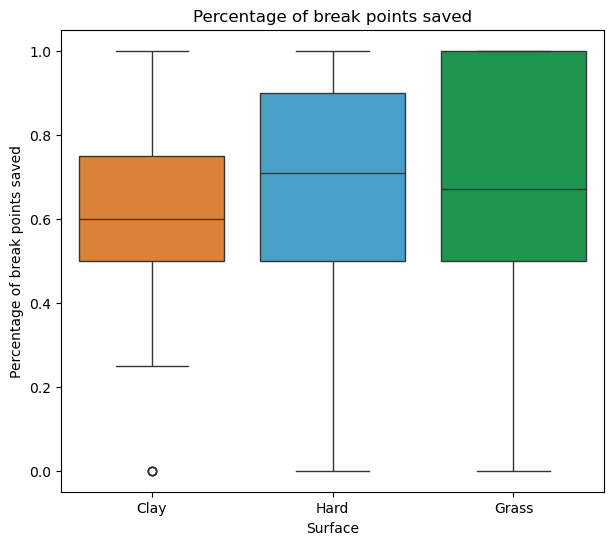

In [61]:
#Create a "Average Break Point Saved Percentage by Serve Type" plot 
fig = plt.figure(figsize = (7,6))
ax_8 = sns.boxplot(data = js_bp, x = 'surface', y = 'bp_saved_pct', palette = surface_colors)
ax_8.set(xlabel = 'Surface', ylabel = 'Percentage of break points saved', \
         title = 'Percentage of break points saved')

plt.show()

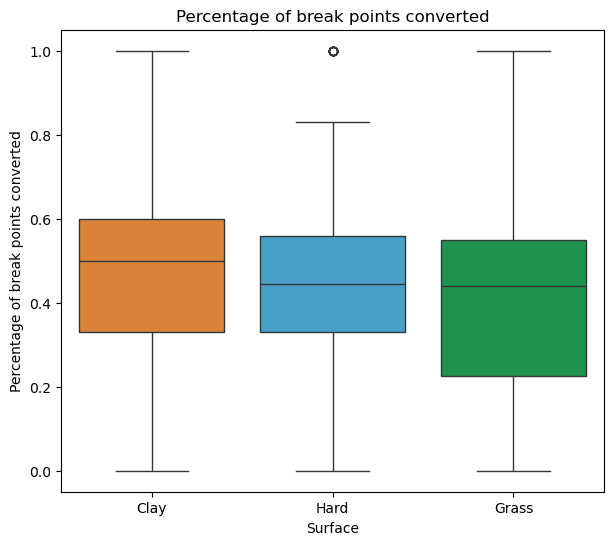

In [62]:
#Create a "Average Break Point Converted Percentage by Serve Type" plot 
fig = plt.figure(figsize = (7,6))
ax_9 = sns.boxplot(data = js_bp, x = 'surface', y = 'bp_won_pct', palette = surface_colors)
ax_9.set(xlabel = 'Surface', ylabel = 'Percentage of break points converted', \
         title = 'Percentage of break points converted')

plt.show()

**Conclusion**: 
- Jannik Sinner faces the most break points on clay (8%) but saves the lowest percentage (61%). On grass, he faces the fewest break points (5%) and saves the most (69%). Hard court performance is in between. He faces 6% of break points and saves 67% of break points.
- Jannik Sinner has the highest break point conversion on Clay (50%), followed by Hard (45%) and Grass (43%).